<a href="https://colab.research.google.com/github/alecseev-dp/math_stat/blob/laba1/Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторная работа по статистическому анализу №1 (Регрессия)

* Используемый датасет: [Набор данных заявок в службу поддержки](https://www.kaggle.com/datasets/suraj520/customer-support-ticket-dataset$0)

[Набор данных для аналитики маркетинга и электронной коммерции](https://www.kaggle.com/datasets/geethasagarbonthu/marketing-and-e-commerce-analytics-dataset?select=campaigns.csv$0)


Задача: Прогнозирование стоимости следующей покупки или LTV (Ценности клиента)
• Что предсказываем: Какую сумму (transaction_amount) потратит конкретный пользователь в будущем или сколько денег он принесет компании за всё время.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler

from google.colab import drive
drive.mount('/content/drive')

import kagglehub

%config InlineBackend.figure_format = 'retina'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# ДФ с скрытыми прямые изолированные связями

In [2]:
df1 = pd.read_csv("/content/drive/MyDrive/math_static/5_семестр/archive/campaigns.csv")
df2 = pd.read_csv("/content/drive/MyDrive/math_static/5_семестр/archive/customers.csv")
df3 = pd.read_csv("/content/drive/MyDrive/math_static/5_семестр/archive/events.csv")
df4 = pd.read_csv("/content/drive/MyDrive/math_static/5_семестр/archive/products.csv")
df5 = pd.read_csv("/content/drive/MyDrive/math_static/5_семестр/archive/transactions.csv")

In [3]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   campaign_id      50 non-null     int64  
 1   channel          50 non-null     object 
 2   objective        50 non-null     object 
 3   start_date       50 non-null     object 
 4   end_date         50 non-null     object 
 5   target_segment   50 non-null     object 
 6   expected_uplift  50 non-null     float64
dtypes: float64(1), int64(1), object(5)
memory usage: 2.9+ KB


In [4]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   customer_id          100000 non-null  int64 
 1   signup_date          100000 non-null  object
 2   country              100000 non-null  object
 3   age                  100000 non-null  int64 
 4   gender               100000 non-null  object
 5   loyalty_tier         100000 non-null  object
 6   acquisition_channel  100000 non-null  object
dtypes: int64(2), object(5)
memory usage: 5.3+ MB


In [5]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000000 entries, 0 to 1999999
Data columns (total 12 columns):
 #   Column                Dtype  
---  ------                -----  
 0   event_id              int64  
 1   timestamp             object 
 2   customer_id           int64  
 3   session_id            int64  
 4   event_type            object 
 5   product_id            float64
 6   device_type           object 
 7   traffic_source        object 
 8   campaign_id           int64  
 9   page_category         object 
 10  session_duration_sec  float64
 11  experiment_group      object 
dtypes: float64(2), int64(4), object(6)
memory usage: 183.1+ MB


In [6]:
print(df3.nunique())

event_id                2000000
timestamp               1977065
customer_id              100000
session_id               633462
event_type                    5
product_id                 2000
device_type                   3
traffic_source               10
campaign_id                  51
page_category                 5
session_duration_sec      16524
experiment_group              3
dtype: int64


In [7]:
df4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   product_id   2000 non-null   int64  
 1   category     2000 non-null   object 
 2   brand        2000 non-null   object 
 3   base_price   2000 non-null   float64
 4   launch_date  2000 non-null   object 
 5   is_premium   2000 non-null   int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 93.9+ KB


In [8]:
df5.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103127 entries, 0 to 103126
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    103127 non-null  int64  
 1   timestamp         103127 non-null  object 
 2   customer_id       103127 non-null  int64  
 3   product_id        92678 non-null   float64
 4   quantity          103127 non-null  int64  
 5   discount_applied  103127 non-null  float64
 6   gross_revenue     92678 non-null   float64
 7   campaign_id       103127 non-null  int64  
 8   refund_flag       103127 non-null  int64  
dtypes: float64(3), int64(5), object(1)
memory usage: 7.1+ MB


In [9]:
df_actions = pd.merge(df3, df5, on=['customer_id', 'product_id', 'campaign_id'], how='outer')

# Присоединяем к действиям справочник клиентов (df2)
df_with_customers = pd.merge(df_actions, df2, on='customer_id', how='left')

#  Присоединяем справочник товаров (df4)
df_with_products = pd.merge(df_with_customers, df4, on='product_id', how='left')

# Присоединяем справочник маркетинговых кампаний (df1)
df = pd.merge(df_with_products, df1, on='campaign_id', how='left')

# Выводим размер получившейся общей таблицы и первые 5 строк
print(f"Итоговый размер таблицы: {df.shape}")
df.head()

Итоговый размер таблицы: (2000092, 35)


,event_id,timestamp_x,customer_id,session_id,event_type,product_id,device_type,traffic_source,campaign_id,page_category,...,brand,base_price,launch_date,is_premium,channel,objective,start_date,end_date,target_segment,expected_uplift
0,1859189,2023-08-13 08:11:55,1,525632,click,231.0,desktop,Organic,0,Cart,...,Brand_37,93.76,2021-03-22,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,365357,2023-02-01 18:21:05,1,107643,view,303.0,desktop,Social,41,PDP,...,Brand_48,44.40,2023-11-27,0.0,Social,Retention,2023-04-09,2023-04-17,All,0.058
2,1593996,2022-04-13 13:26:15,1,562644,view,451.0,mobile,Email,40,PDP,...,Brand_2,34.22,2021-12-28,0.0,Display,Cross-sell,2022-07-25,2022-09-07,New Customers,0.105
3,42433,2023-05-20 00:31:20,1,634043,view,586.0,mobile,Paid Search,46,PLP,...,Brand_46,107.95,2022-10-01,1.0,Social,Cross-sell,2023-03-23,2023-04-17,All,0.030
4,712827,2023-07-11 09:44:46,1,132608,view,592.0,mobile,Organic,0,Home,...,Brand_48,71.12,2023-03-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000092 entries, 0 to 2000091
Data columns (total 35 columns):
 #   Column                Dtype  
---  ------                -----  
 0   event_id              int64  
 1   timestamp_x           object 
 2   customer_id           int64  
 3   session_id            int64  
 4   event_type            object 
 5   product_id            float64
 6   device_type           object 
 7   traffic_source        object 
 8   campaign_id           int64  
 9   page_category         object 
 10  session_duration_sec  float64
 11  experiment_group      object 
 12  transaction_id        float64
 13  timestamp_y           object 
 14  quantity              float64
 15  discount_applied      float64
 16  gross_revenue         float64
 17  refund_flag           float64
 18  signup_date           object 
 19  country               object 
 20  age                   int64  
 21  gender                object 
 22  loyalty_tier          object 
 23  acquisi

In [11]:
df.isnull().sum()

,0
event_id,0
timestamp_x,0
customer_id,0
session_id,0
event_type,0
product_id,200457
device_type,40303
traffic_source,0
campaign_id,0
page_category,0


In [12]:
# Группируем данные по уникальным клиентам
df_static_data = df.groupby('customer_id').agg(

    # ТАРГЕТ
    # Общая сумма покупок клиента (Грязная выручка)
    target_gross_revenue=('gross_revenue', lambda x: x.sum(skipna=True)),

    # ПРИЗНАКИ
    # 1. Поведенческие факторы (из логов кликов)
    total_clicks=('event_id', 'count'),                          # Всего действий на сайте
    unique_sessions=('session_id', 'nunique'),                   # Сколько раз заходил на сайт
    avg_session_duration=('session_duration_sec', 'mean'),        # Среднее время на сайте в секундах
    unique_event_types=('event_type', 'nunique'),                # Разнообразие действий (просмотр, корзина и т.д.)

    # 2. Факторы покупок
    total_items_bought=('quantity', lambda x: x.sum(skipna=True)),# Сколько всего единиц товара купил
    avg_discount=('discount_applied', 'mean'),                   # Средняя скидка, которую он получал
    refund_count=('refund_flag', lambda x: x.sum(skipna=True)),  # Сколько раз оформлял возврат товара

    # 3. Личные данные клиента (берем моду — самое частое/стабильное значение)
    age=('age', 'first'),                                         # Возраст клиента
    gender=('gender', lambda x: x.mode()[0] if not x.mode().empty else 'Unknown'),
    country=('country', lambda x: x.mode()[0] if not x.mode().empty else 'Unknown'),
    loyalty_tier=('loyalty_tier', lambda x: x.mode()[0] if not x.mode().empty else 'Unknown'),
    acq_channel=('acquisition_channel', lambda x: x.mode()[0] if not x.mode().empty else 'Unknown'),

    # 4. Интересы к товарам и брендам
    unique_products_looked=('product_id', 'nunique'),            # Сколько разных товаров изучил
    unique_categories=('category', 'nunique'),                    # Сколько разных категорий товаров посмотрел
    unique_brands=('brand', 'nunique'),                           # Сколько разных брендов изучил
    avg_base_price=('base_price', 'mean'),                        # Средняя базовая цена просматриваемых товаров
    premium_interact_ratio=('is_premium', 'mean'),                # Доля премиум-товаров среди всех его просмотров

    # 5. Взаимодействие с маркетингом
    unique_campaigns=('campaign_id', 'nunique'),                  # В скольких маркетинговых кампаниях участвовал
    unique_marketing_channels=('channel', 'nunique'),             # Из скольких каналов рекламы пришел
    avg_expected_uplift=('expected_uplift', 'mean')              # Средний ожидаемый эффект от рекламы, на которую он среагировал
).reset_index()

# Если клиент только кликал, но ничего не купил, его траты и количество покупок равны 0
df_static_data['target_gross_revenue'] = df_static_data['target_gross_revenue'].fillna(0)
df_static_data['total_items_bought'] = df_static_data['total_items_bought'].fillna(0)
df_static_data['refund_count'] = df_static_data['refund_count'].fillna(0)

# Заполняем среднюю скидку нулем, если покупок со скидкой не было
df_static_data['avg_discount'] = df_static_data['avg_discount'].fillna(0)

print(f"Новый размер таблицы для регрессии: {df_static_data.shape}")
df_static_data.head()

Новый размер таблицы для регрессии: (100000, 22)


,customer_id,target_gross_revenue,total_clicks,unique_sessions,avg_session_duration,unique_event_types,total_items_bought,avg_discount,refund_count,age,...,loyalty_tier,acq_channel,unique_products_looked,unique_categories,unique_brands,avg_base_price,premium_interact_ratio,unique_campaigns,unique_marketing_channels,avg_expected_uplift
0,1,0.00,18,18,189.100000,3,0.0,0.00,0.0,48,...,Bronze,Referral,18,6,17,58.903889,0.444444,13,4,0.079692
1,2,60.09,19,19,114.547368,5,1.0,0.05,0.0,36,...,Silver,Organic,17,6,16,82.422353,0.411765,6,3,0.076400
2,3,0.00,14,14,131.714286,3,0.0,0.00,0.0,35,...,Silver,Organic,13,5,13,49.846923,0.307692,5,4,0.096250
3,4,0.00,23,23,138.173913,4,0.0,0.00,0.0,45,...,Silver,Paid Search,20,6,19,72.226500,0.600000,13,5,0.091417
4,5,0.00,11,11,115.054545,4,0.0,0.00,0.0,53,...,Silver,Organic,9,6,9,56.952222,0.333333,5,4,0.070250


In [13]:
print(df_static_data.isnull().sum())
df_static_data.dropna(inplace=True)

customer_id                  0
target_gross_revenue         0
total_clicks                 0
unique_sessions              0
avg_session_duration         0
unique_event_types           0
total_items_bought           0
avg_discount                 0
refund_count                 0
age                          0
gender                       0
country                      0
loyalty_tier                 0
acq_channel                  0
unique_products_looked       0
unique_categories            0
unique_brands                0
avg_base_price               0
premium_interact_ratio       0
unique_campaigns             0
unique_marketing_channels    0
avg_expected_uplift          2
dtype: int64


In [14]:
print(df_static_data.isnull().sum())

customer_id                  0
target_gross_revenue         0
total_clicks                 0
unique_sessions              0
avg_session_duration         0
unique_event_types           0
total_items_bought           0
avg_discount                 0
refund_count                 0
age                          0
gender                       0
country                      0
loyalty_tier                 0
acq_channel                  0
unique_products_looked       0
unique_categories            0
unique_brands                0
avg_base_price               0
premium_interact_ratio       0
unique_campaigns             0
unique_marketing_channels    0
avg_expected_uplift          0
dtype: int64


In [15]:
df_static_data = df_static_data[df_static_data['gender'] != 'Other']

In [16]:
df_static_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 96058 entries, 0 to 99999
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                96058 non-null  int64  
 1   target_gross_revenue       96058 non-null  float64
 2   total_clicks               96058 non-null  int64  
 3   unique_sessions            96058 non-null  int64  
 4   avg_session_duration       96058 non-null  float64
 5   unique_event_types         96058 non-null  int64  
 6   total_items_bought         96058 non-null  float64
 7   avg_discount               96058 non-null  float64
 8   refund_count               96058 non-null  float64
 9   age                        96058 non-null  int64  
 10  gender                     96058 non-null  object 
 11  country                    96058 non-null  object 
 12  loyalty_tier               96058 non-null  object 
 13  acq_channel                96058 non-null  object 


In [17]:
df_static_data.nunique()

,0
customer_id,96058
target_gross_revenue,27128
total_clicks,37
unique_sessions,37
avg_session_duration,74785
unique_event_types,5
total_items_bought,21
avg_discount,94
refund_count,6
age,53


In [18]:
continuous_features = []
binary_features = []
categorical_features = []

for column in df_static_data.columns:
    n_unique = df_static_data[column].nunique()

    if n_unique > 50:
        continuous_features.append(column)
    elif n_unique <= 2:
        binary_features.append(column)
    else:
        categorical_features.append(column)

print(f"Непрерывные признаки (>100 уник. значений): {len(continuous_features)}")
print(continuous_features, "\n")

print(f"Бинарные признаки (<=2 уник. значений): {len(binary_features)}")
print(binary_features, "\n")

print(f"Категориальные признаки (от 3 до 100 уник. значений): {len(categorical_features)}")
print(categorical_features)

Непрерывные признаки (>100 уник. значений): 8
['customer_id', 'target_gross_revenue', 'avg_session_duration', 'avg_discount', 'age', 'avg_base_price', 'premium_interact_ratio', 'avg_expected_uplift'] 

Бинарные признаки (<=2 уник. значений): 1
['gender'] 

Категориальные признаки (от 3 до 100 уник. значений): 13
['total_clicks', 'unique_sessions', 'unique_event_types', 'total_items_bought', 'refund_count', 'country', 'loyalty_tier', 'acq_channel', 'unique_products_looked', 'unique_categories', 'unique_brands', 'unique_campaigns', 'unique_marketing_channels']


In [19]:
df_static_data.describe()

,customer_id,target_gross_revenue,total_clicks,unique_sessions,avg_session_duration,unique_event_types,total_items_bought,avg_discount,refund_count,age,unique_products_looked,unique_categories,unique_brands,avg_base_price,premium_interact_ratio,unique_campaigns,unique_marketing_channels,avg_expected_uplift
count,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000,96058.000000
mean,49974.507173,83.684902,20.003446,20.002165,130.637202,4.409961,1.456474,0.026583,0.030742,35.222782,17.917571,5.569562,16.398874,72.131518,0.500040,10.065336,4.300079,0.086611
std,28860.293197,131.602338,4.462833,4.461720,36.481858,0.659174,1.682072,0.046622,0.179188,9.593661,4.209191,0.617016,3.680659,12.681251,0.121259,2.721507,0.772032,0.011951
min,1.000000,-736.230000,4.000000,4.000000,47.054545,1.000000,0.000000,0.000000,0.000000,18.000000,4.000000,2.000000,4.000000,17.996250,0.000000,2.000000,1.000000,0.022000
25%,24981.250000,0.000000,17.000000,17.000000,109.254659,4.000000,0.000000,0.000000,0.000000,28.000000,15.000000,5.000000,14.000000,63.414706,0.421053,8.000000,4.000000,0.078857
50%,49947.500000,34.210000,20.000000,20.000000,123.336932,5.000000,1.000000,0.000000,0.000000,35.000000,18.000000,6.000000,16.000000,71.431098,0.500000,10.000000,4.000000,0.086714
75%,74954.750000,122.617500,23.000000,23.000000,141.343646,5.000000,2.000000,0.050000,0.000000,42.000000,21.000000,6.000000,19.000000,80.057467,0.578947,12.000000,5.000000,0.094500
max,100000.000000,1858.320000,41.000000,41.000000,674.395238,5.000000,22.000000,0.200000,5.000000,70.000000,38.000000,6.000000,33.000000,153.961000,1.000000,24.000000,5.000000,0.144000


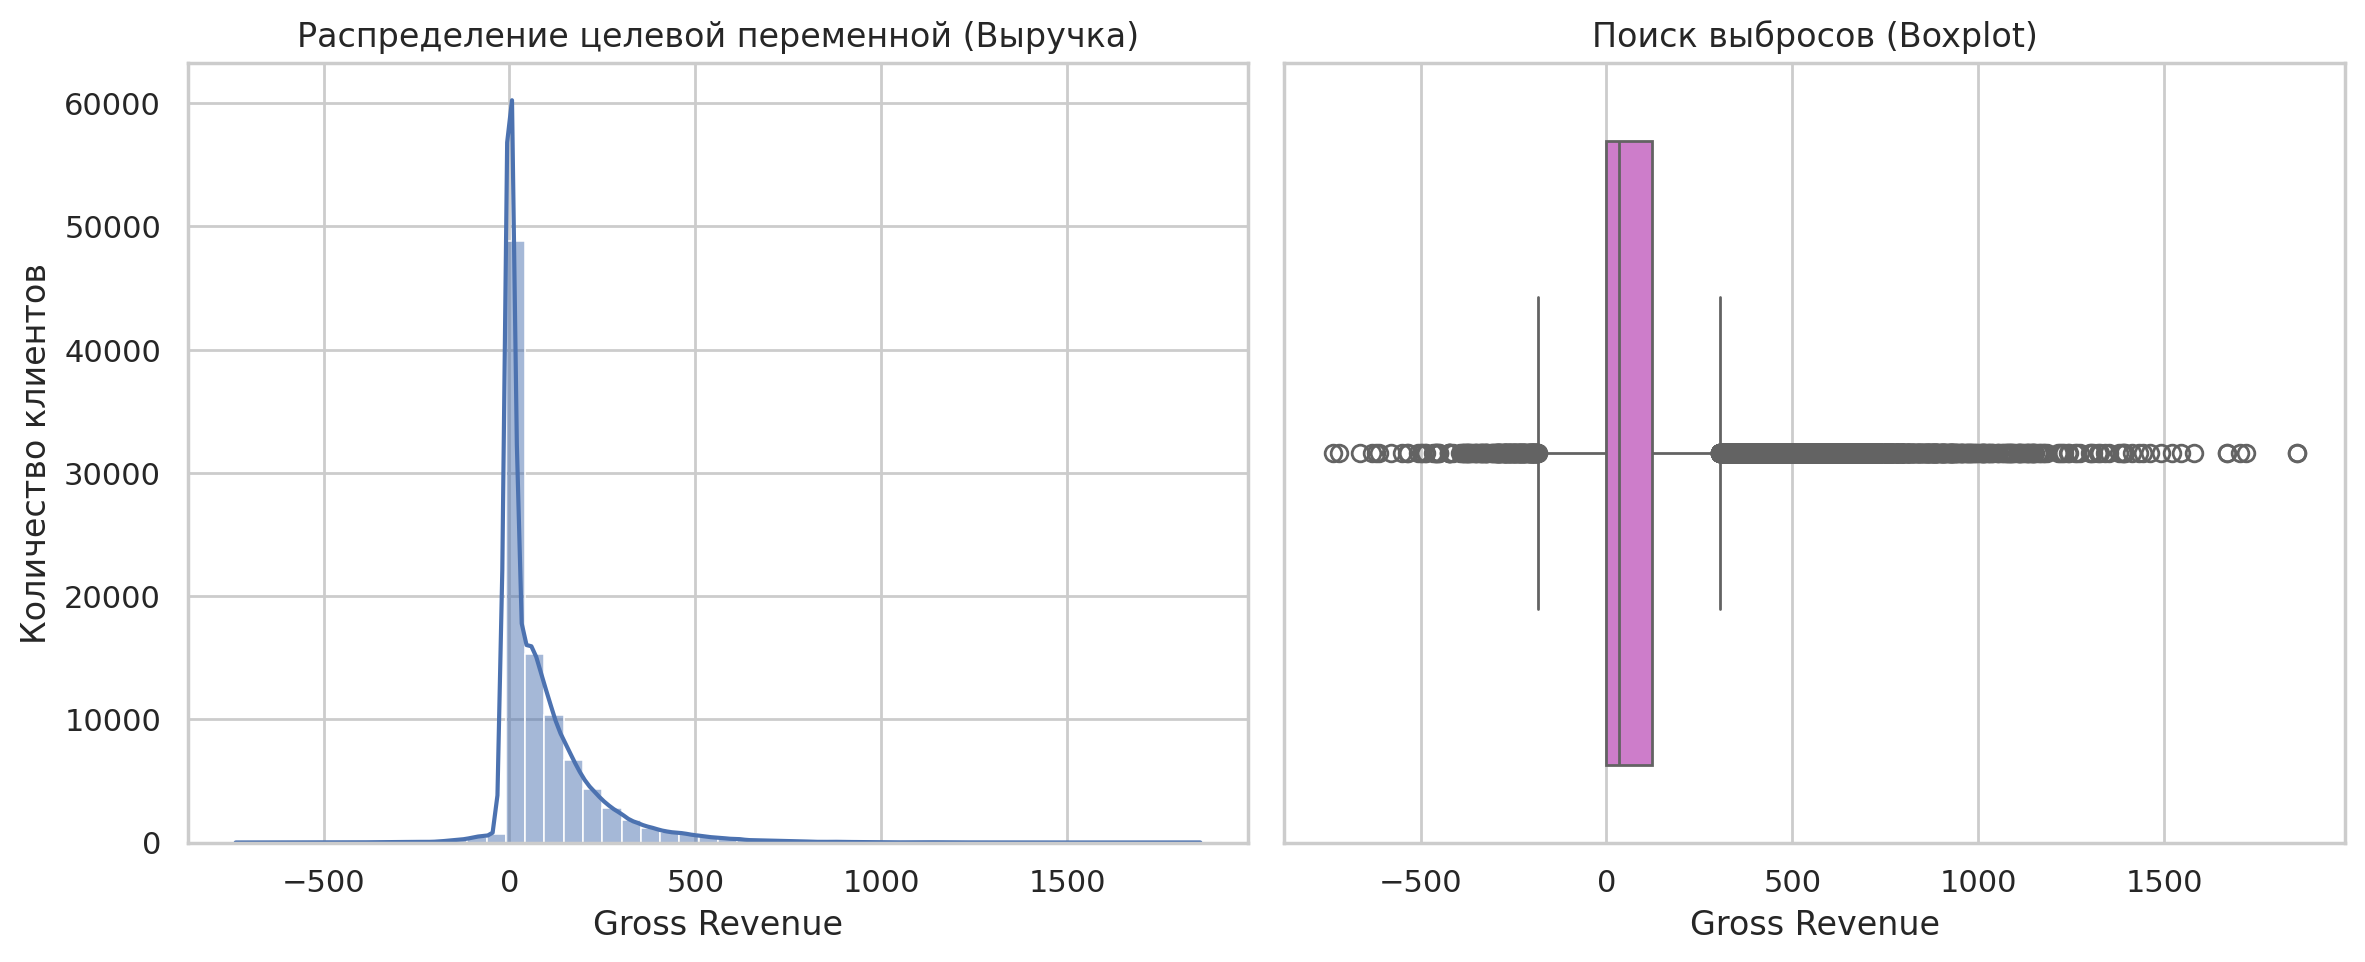

In [20]:
# Настраиваем стиль графиков
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 5))

#  Гистограмма распределения таргета
plt.subplot(1, 2, 1)
sns.histplot(df_static_data['target_gross_revenue'], bins=50, kde=True)
plt.title('Распределение целевой переменной (Выручка)')
plt.xlabel('Gross Revenue')
plt.ylabel('Количество клиентов')

# Боксплот
plt.subplot(1, 2, 2)
sns.boxplot(x=df_static_data['target_gross_revenue'], color='orchid')
plt.title('Поиск выбросов (Boxplot)')
plt.xlabel('Gross Revenue')

plt.tight_layout()
plt.show()


In [21]:
def remove_outliers_percentile(dataframe, columns_list, lower_quantile=0.25, upper_quantile=0.75, tol=1e-5, max_iter=10):

    df_clean = dataframe.copy()
    initial_rows = len(df_clean)

    print("Старт итеративной чистки по медиане...\n")

    for column in columns_list:
        iteration = 0
        median_diff = float('inf')

        # Запускаем цикл чистки для конкретного столбца
        while median_diff > tol and iteration < max_iter:
            current_rows = len(df_clean)
            if current_rows == 0:
                break

            # Считаем медиану ДО текущего шага чистки
            old_median = df_clean[column].median()

            # Вычисляем текущие границы квантилей
            lower_limit = df_clean[column].quantile(lower_quantile)
            upper_limit = df_clean[column].quantile(upper_quantile)

            # Фильтруем данные по границам
            if df_clean[column].min() >= 0:
                df_next = df_clean[df_clean[column] <= upper_limit]
            else:
                df_next = df_clean[(df_clean[column] >= lower_limit) & (df_clean[column] <= upper_limit)]

            # Если после фильтрации строки не удалились (границы совпали с данными), выходим
            if len(df_next) == current_rows:
                break

            # Считаем медиану ПОСЛЕ чистки
            new_median = df_next[column].median()

            median_diff = abs(new_median - old_median)

            # Обновляем датафрейм для следующей итерации
            df_clean = df_next.copy()
            iteration += 1

        print(f"[{column}] Завершено за {iteration} итераций.")

    print(f"\nИтоговые результаты конвейера:")
    print(f"Было строк изначально: {initial_rows} | Стало строк в конце: {len(df_clean)}")
    print(f"Всего удалено аномалий: {initial_rows - len(df_clean)} ({((initial_rows - len(df_clean))/initial_rows)*100:.2f}%)")

    return df_clean


In [22]:
#  итеративная чистка для целевой переменной
df_clean_light = remove_outliers_percentile(
    dataframe=df_static_data,
    columns_list=['target_gross_revenue'],
    lower_quantile=0.1,
    upper_quantile=0.9
)

print(f"Размер датасета после очистки только целевой переменной: {df_clean_light.shape}")

Старт итеративной чистки по медиане...

[target_gross_revenue] Завершено за 3 итераций.

Итоговые результаты конвейера:
Было строк изначально: 96058 | Стало строк в конце: 68703
Всего удалено аномалий: 27355 (28.48%)
Размер датасета после очистки только целевой переменной: (68703, 22)


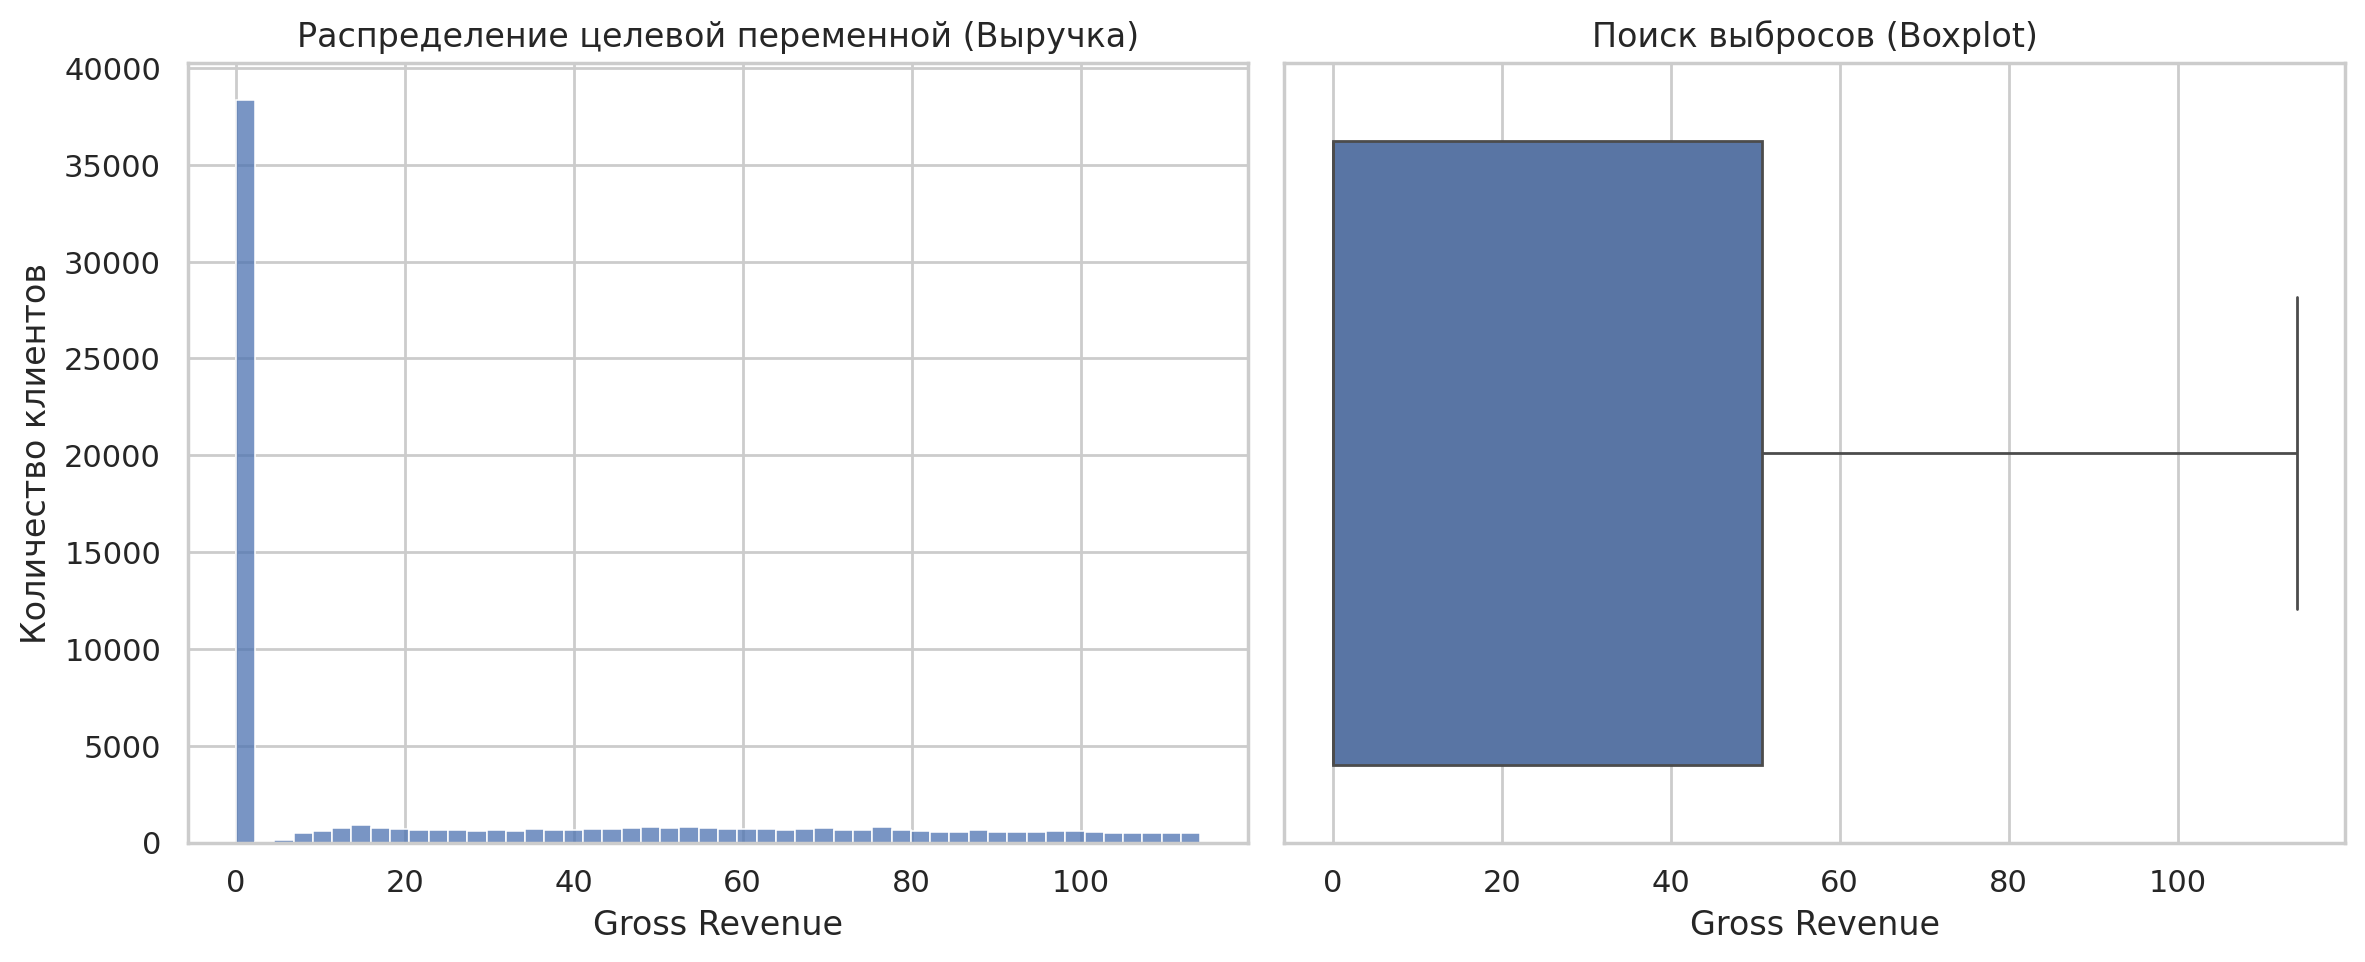

In [23]:
plt.figure(figsize=(12, 5))

#  Гистограмма распределения таргета
plt.subplot(1, 2, 1)
sns.histplot(df_clean_light['target_gross_revenue'], bins=50)
plt.title('Распределение целевой переменной (Выручка)')
plt.xlabel('Gross Revenue')
plt.ylabel('Количество клиентов')

# 2. Боксплот
plt.subplot(1, 2, 2)
sns.boxplot(x=df_clean_light['target_gross_revenue'])
plt.title('Поиск выбросов (Boxplot)')
plt.xlabel('Gross Revenue')

plt.tight_layout()
plt.show()

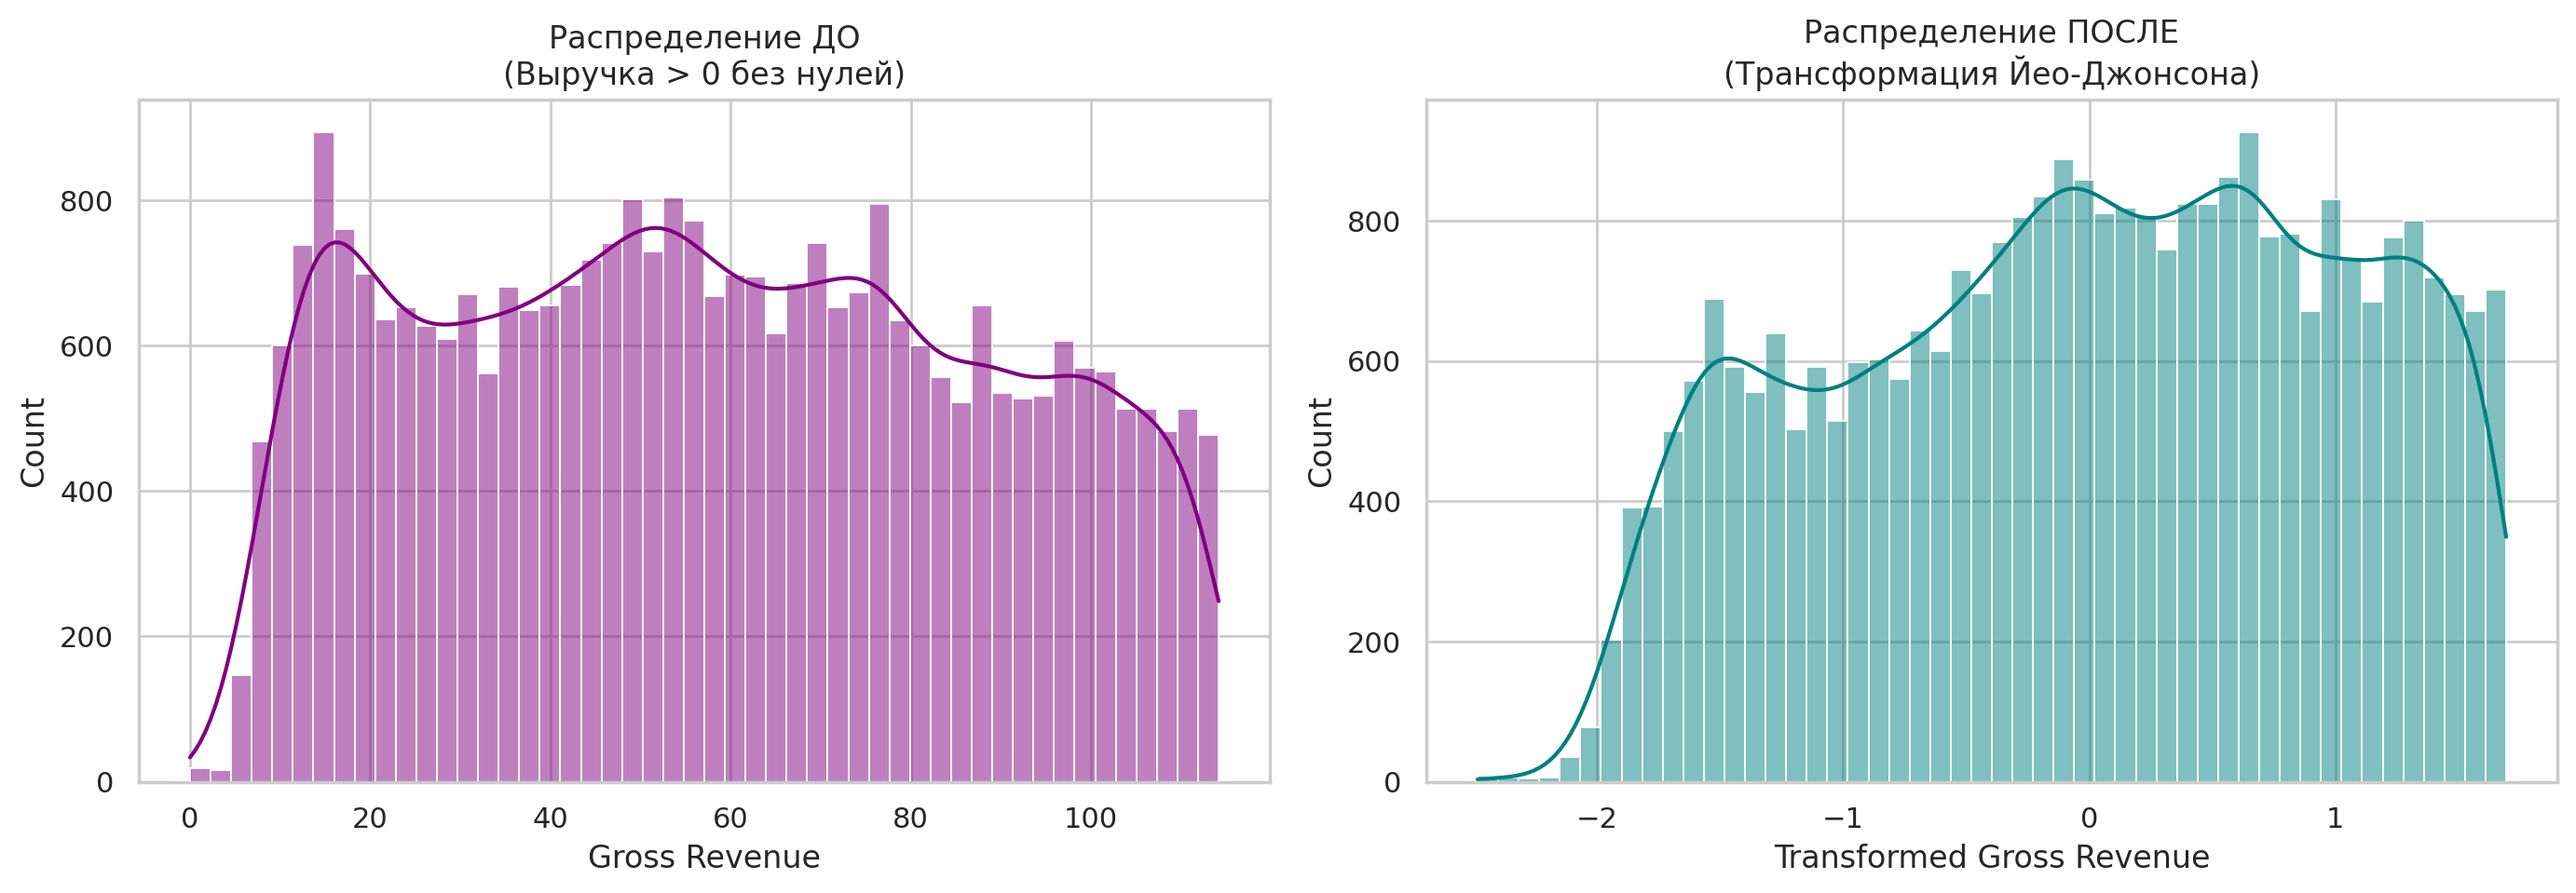

In [24]:
from sklearn.preprocessing import PowerTransformer

#  Фильтруем датасет: убираем нули и оставляем только клиентов с покупками (> 0)
df_clean_light = df_clean_light[df_clean_light['target_gross_revenue'] > 0].copy()

# 2. Инициализируем трансформер Йео-Джонсона
pt = PowerTransformer(method='yeo-johnson')

# Обучаем трансформер на строго положительной выручке и трансформируем её
df_clean_light['target_revenue_transformed'] = pt.fit_transform(df_clean_light[['target_gross_revenue']])

# 4. Визуализируем результат, чтобы сравнить распределения
plt.figure(figsize=(14, 5))

# График ДО (Очищенная выручка без нулей)
plt.subplot(1, 2, 1)
sns.histplot(df_clean_light['target_gross_revenue'], bins=50, kde=True, color='purple')
plt.title('Распределение ДО\n(Выручка > 0 без нулей)')
plt.xlabel('Gross Revenue')

# График ПОСЛЕ (Идеальный колокол после трансформации Йео-Джонсона)
plt.subplot(1, 2, 2)
sns.histplot(df_clean_light['target_revenue_transformed'], bins=50, kde=True, color='teal')
plt.title('Распределение ПОСЛЕ\n(Трансформация Йео-Джонсона)')
plt.xlabel('Transformed Gross Revenue')

plt.tight_layout()
plt.show()


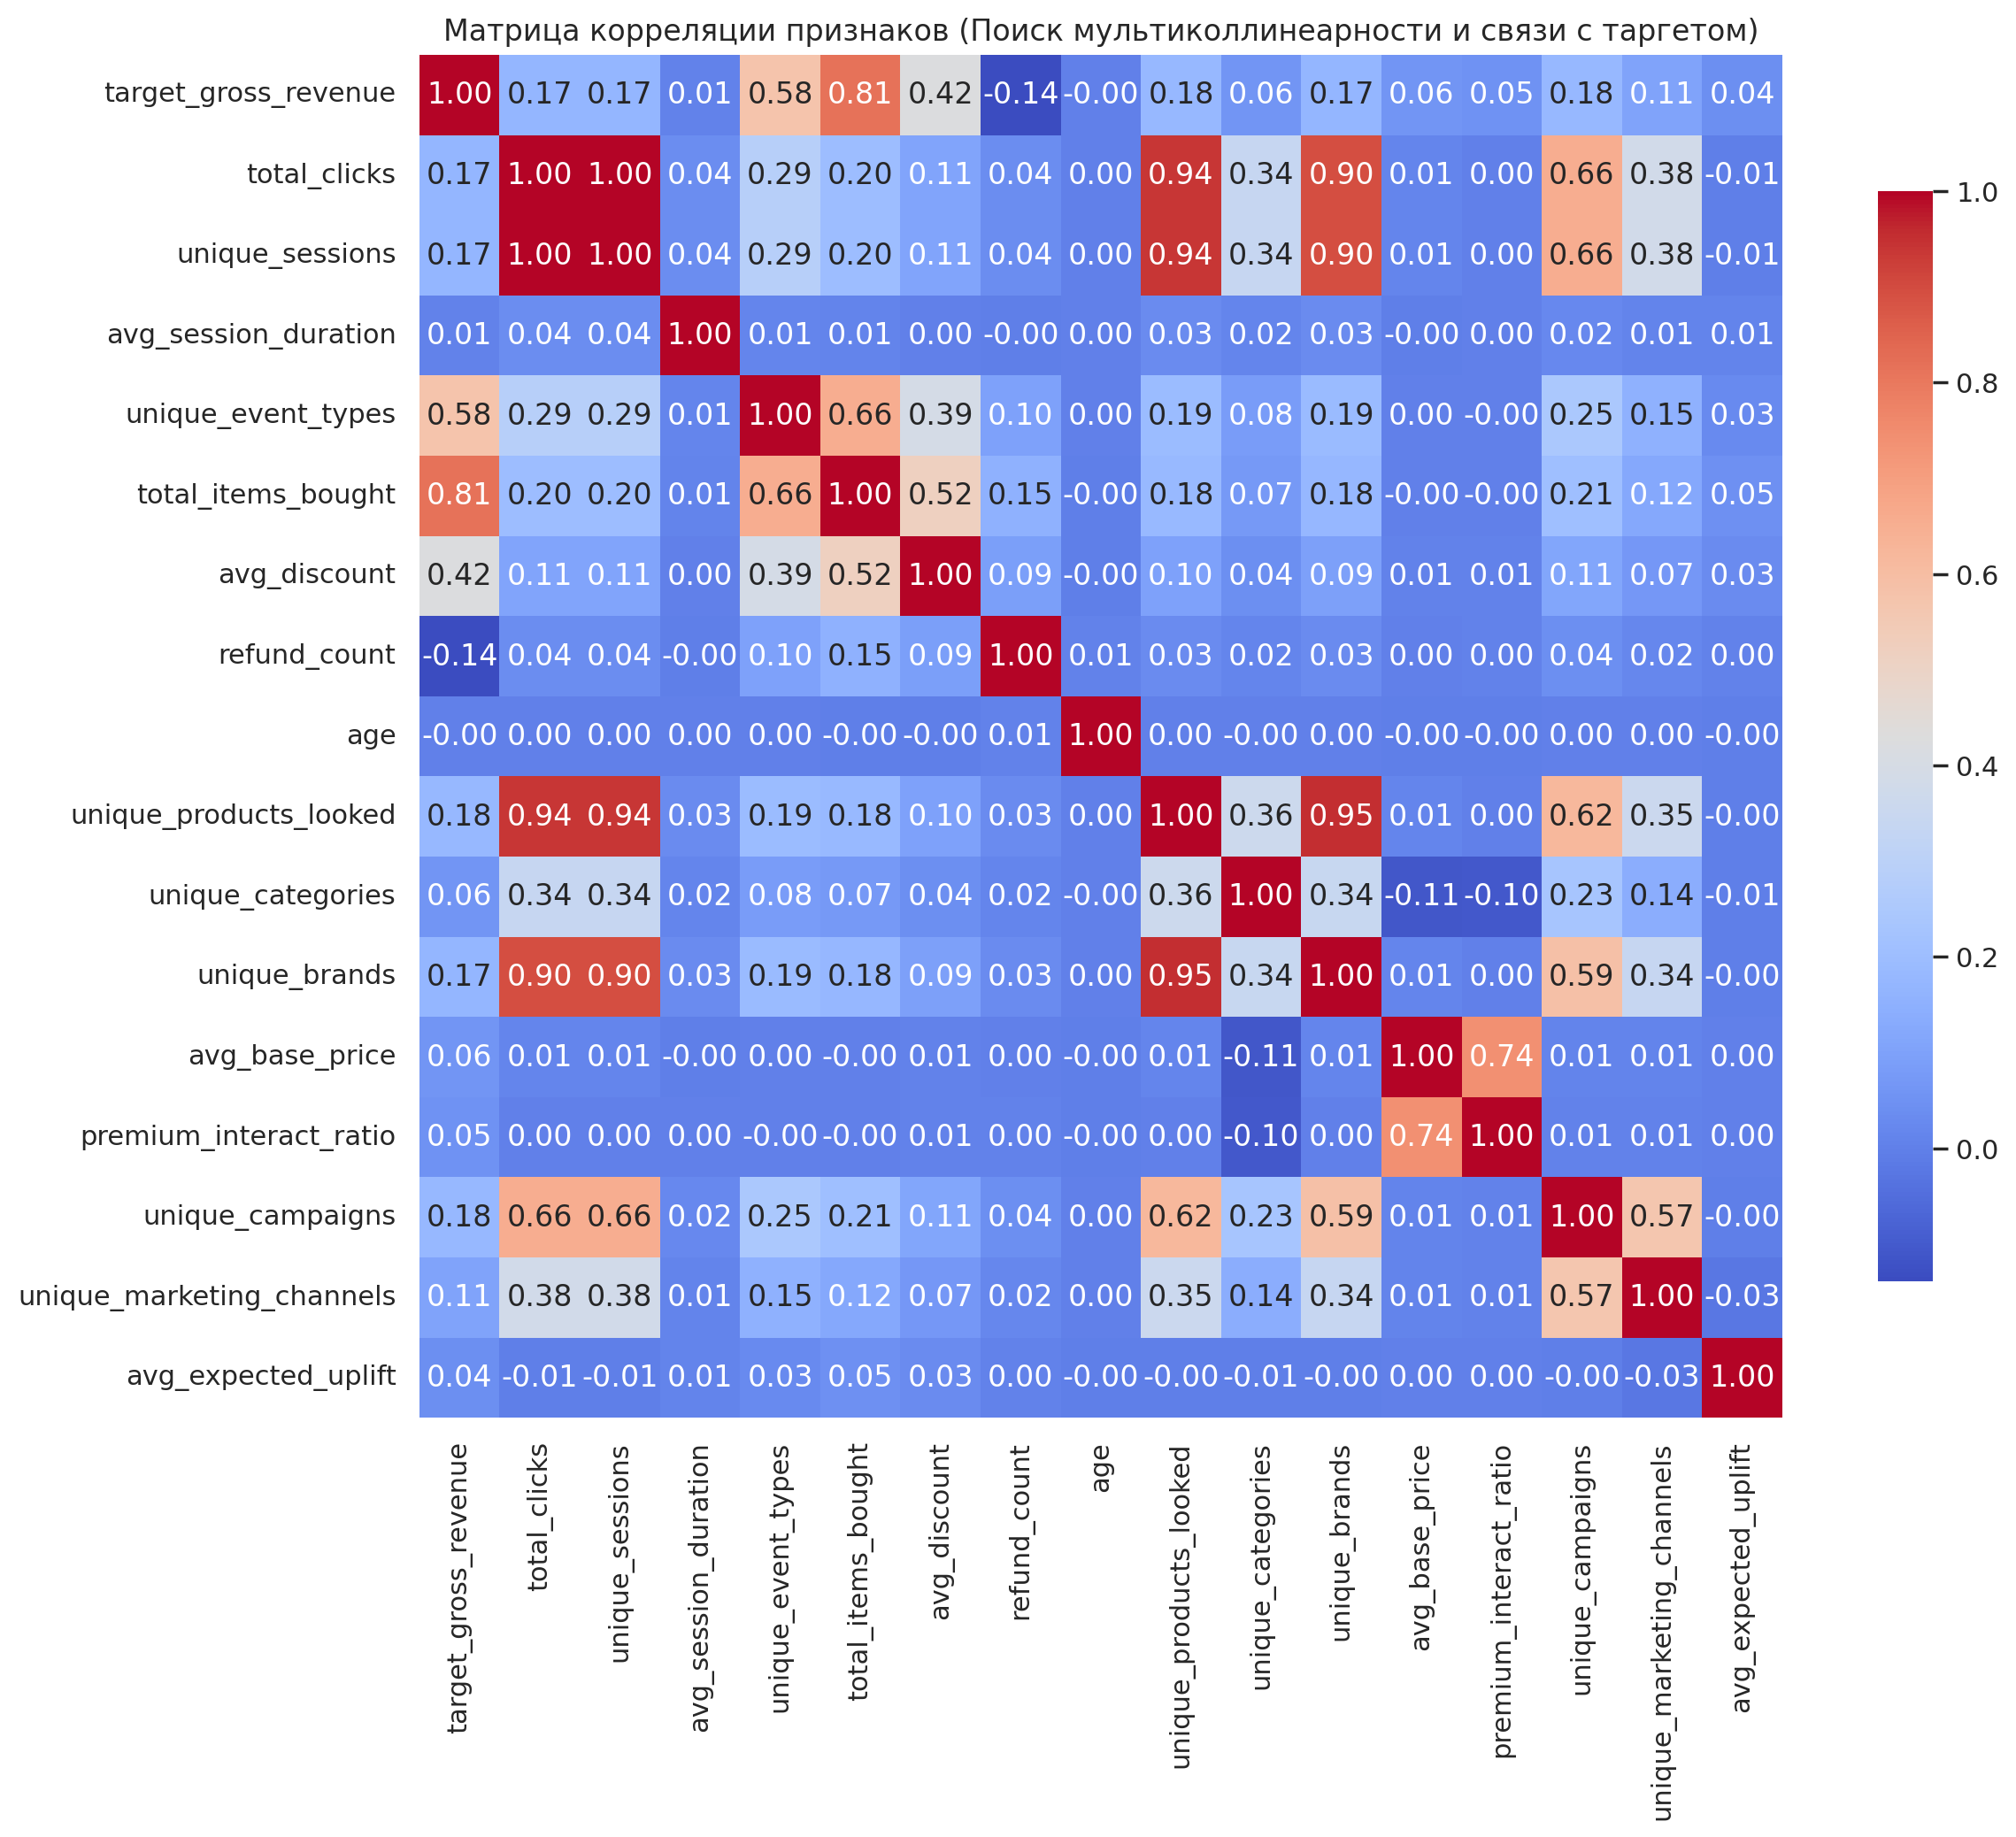

In [25]:
# 1. Выбираем только числовые колонки для корреляции
numeric_cols = df_static_data.select_dtypes(include=[np.number]).columns

# Исключаем customer_id, так как это просто порядковый номер
numeric_cols = [col for col in numeric_cols if col != 'customer_id']

# 2. Считаем матрицу корреляции
corr_matrix = df_static_data[numeric_cols].corr(method='spearman')

# 3. Визуализируем тепловую карту
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})
plt.title('Матрица корреляции признаков (Поиск мультиколлинеарности и связи с таргетом)')
plt.show()

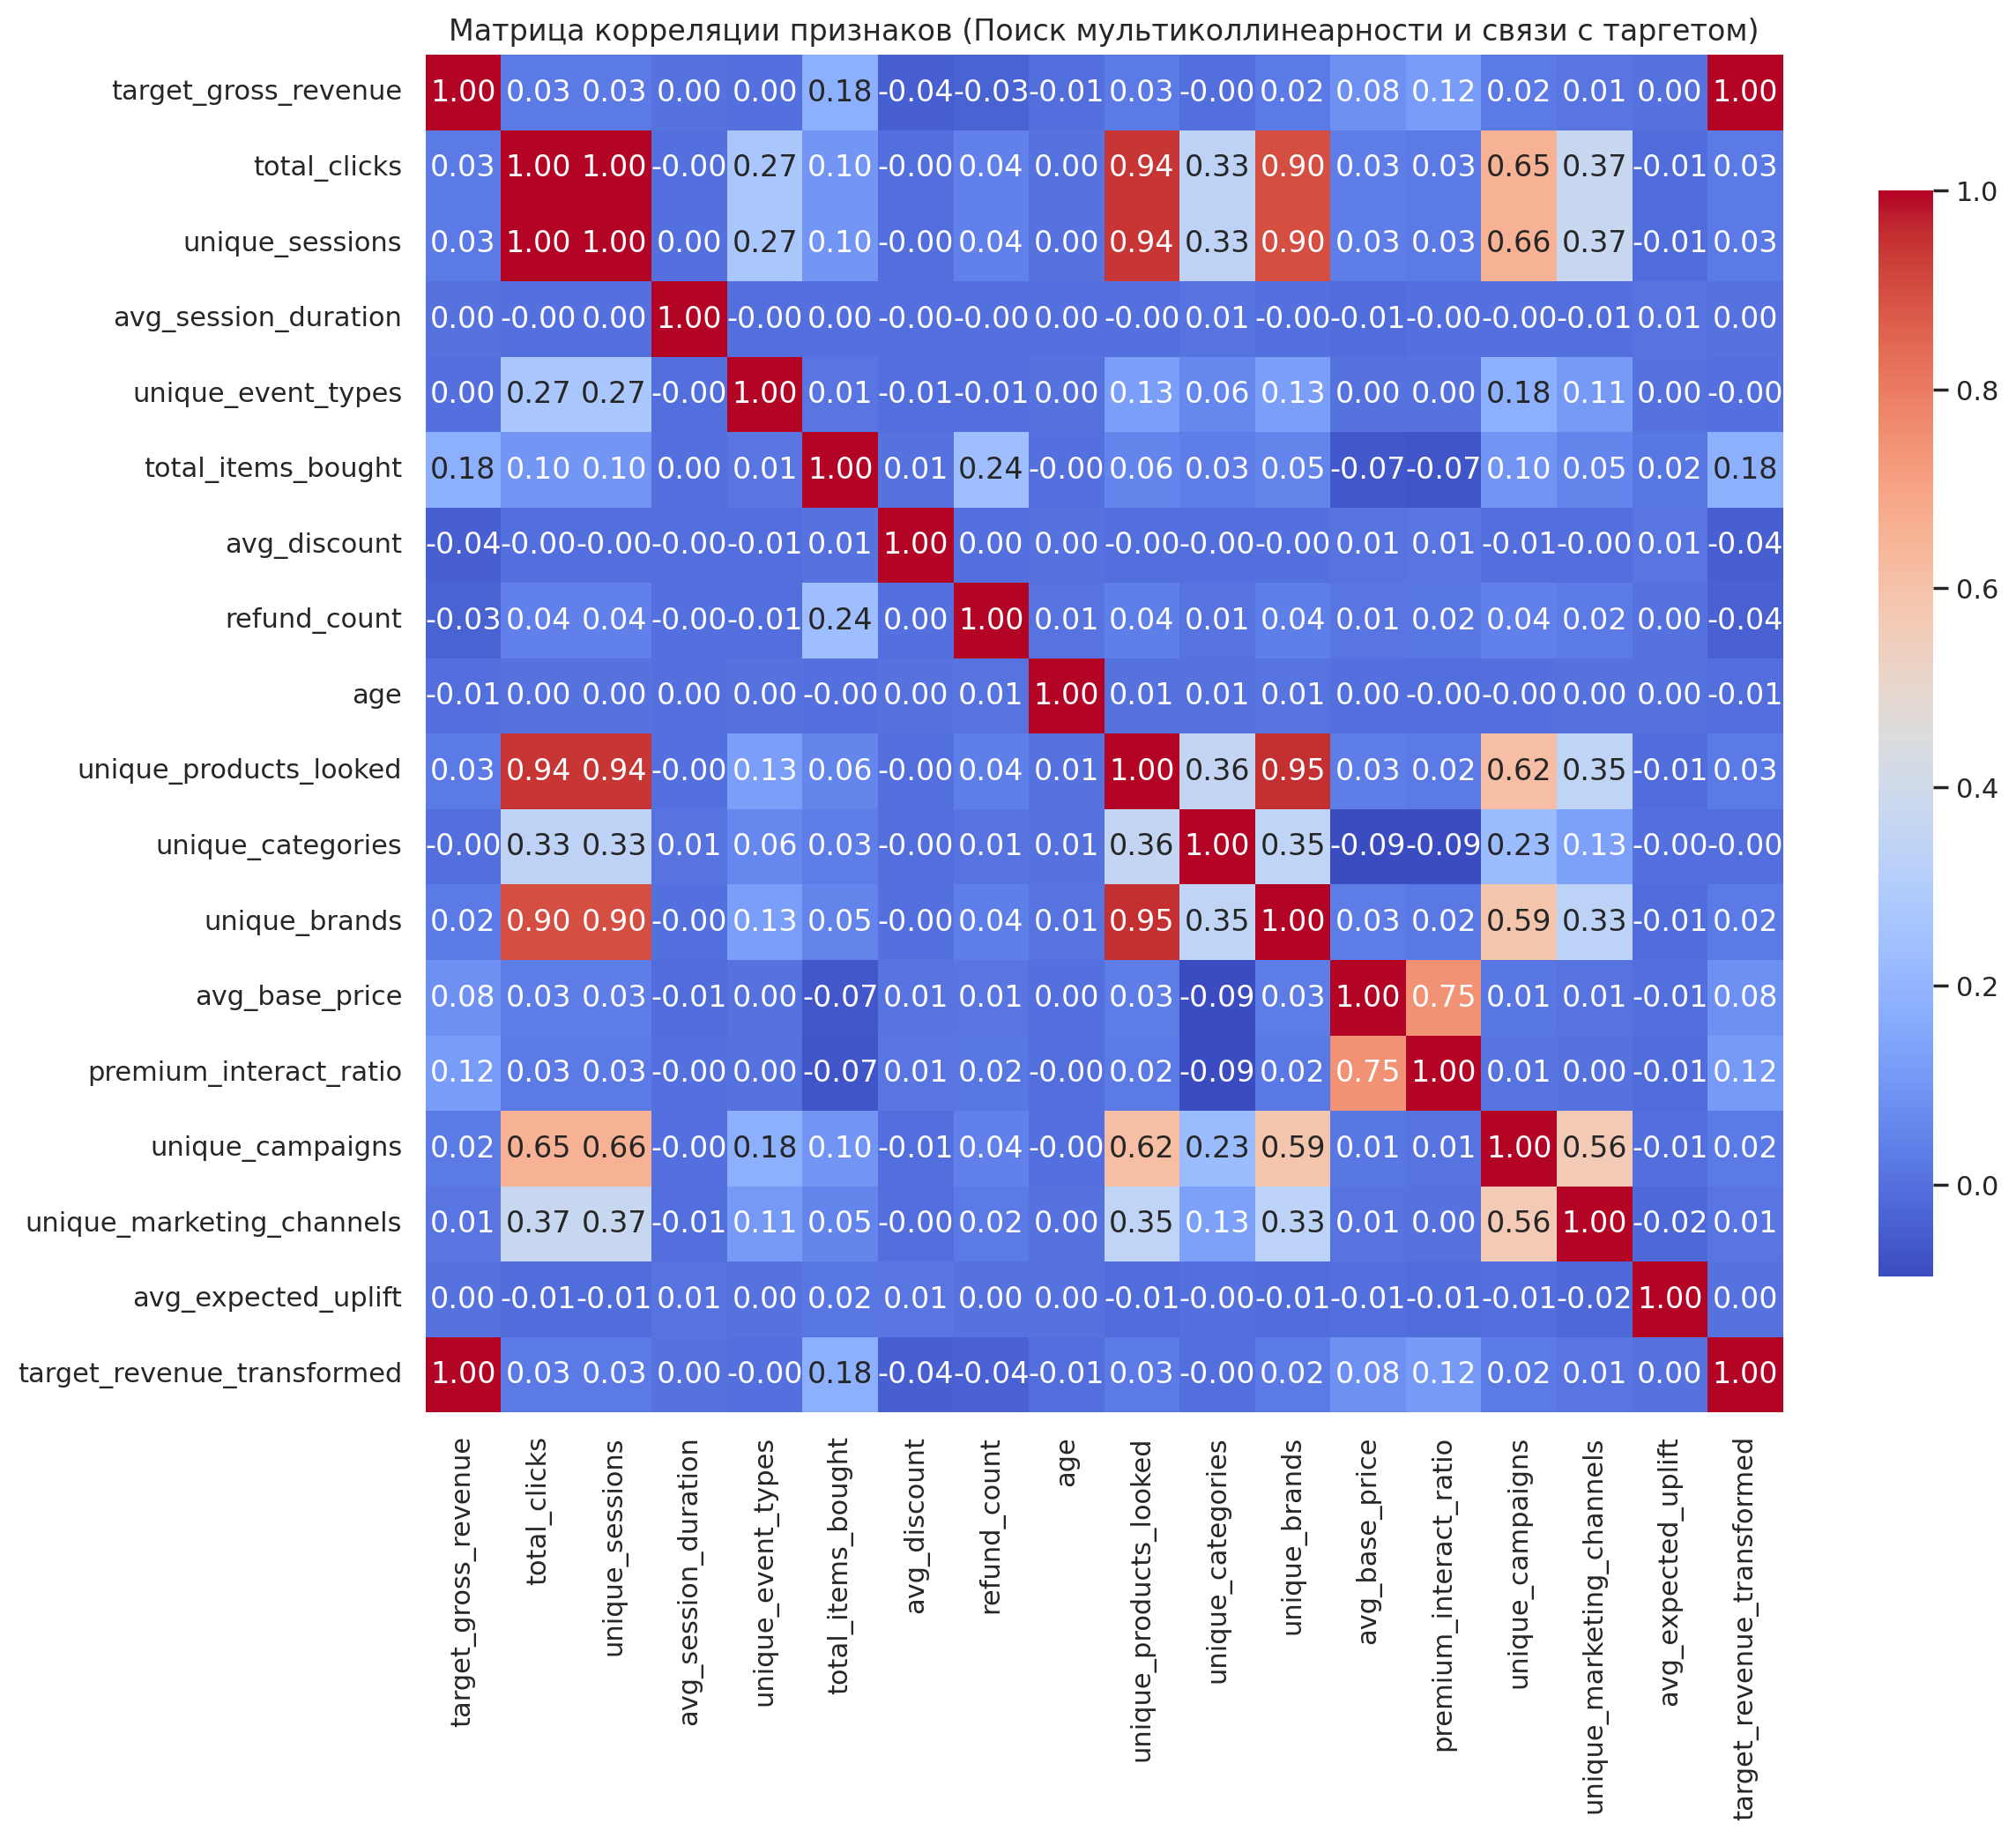

In [26]:
numeric_cols = df_clean_light.select_dtypes(include=[np.number]).columns

# Исключаем customer_id, так как это просто порядковый номер
numeric_cols = [col for col in numeric_cols if col != 'customer_id']

# Считаем матрицу корреляции
corr_matrix = df_clean_light[numeric_cols].corr(method='pearson')

# Визуализируем тепловую карту
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})
plt.title('Матрица корреляции признаков (Поиск мультиколлинеарности и связи с таргетом)')
plt.show()

Линейный коэффициент Пирсона оценивает только строгую прямую линейную связь. Низкие значения корреляции признаков с таргетом говорят о том, что зависимости в данных имеют сложный, нелинейный характер, либо имеют синергетический эффект (работают только в комбинации друг с другом). Именно поэтому использование простой линейной регрессии здесь неэффективно, и необходимо применять методы нелинейного моделирования и регуляризации

#П Подготовка данных к ML

In [27]:
from sklearn.model_selection import train_test_split

def prepare_and_split_data(dataframe, target_column, numeric_features_list):

    y = dataframe[target_column]

    #  Выделяем заданные ЧИСЛОВЫЕ признаки
    X_numeric = dataframe[numeric_features_list]

    # Автоматически находим КАТЕГОРИАЛЬНЫЕ и БИНАРНЫЕ признаки (исключая таргет и customer_id)
    cols_to_exclude = [target_column, 'customer_id']
    categorical_features = [col for col in dataframe.select_dtypes(exclude=[np.number]).columns
                            if col not in cols_to_exclude]

    # Кодируем текст в 0 и 1 через One-Hot Encoding с защитой от dummy-ловушки
    X_categorical = pd.get_dummies(dataframe[categorical_features], drop_first=True)

    # склейка числовые и закодированные категориальные признаки по горизонтали
    X = pd.concat([X_numeric, X_categorical], axis=1)

    # Преобразуем всё в float для стабильной работы моделей
    X = X.astype(float)

    # разбитие данных на три выборки (60 / 20 / 20)
    # Сначала отрезаем 20% под финальный ТЕСТ
    X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Оставшиеся 80% (X_temp) делим на ТРЕЙН (60% от исходного) и ВАЛИДАЦИЮ (20% от исходного)
    X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

    # Выводим отчет о размерах для проверки
    print(f"Выборки успешно подготовлены для целевой переменной: '{target_column}'")
    print(f"Всего признаков в матрице X после кодирования: {X.shape[1]}")
    print(f"Обучающая выборка (Train):     X_train: {X_train.shape}, y_train: {y_train.shape} (60%)")
    print(f"Валидационная выборка (Valid): X_val:   {X_val.shape},  y_val:   {y_val.shape} (20%)")
    print(f"Тестовая выборка (Test):       X_test:  {X_test.shape},  y_test:  {y_test.shape} (20%)")

    return X_train, X_val, X_test, y_train, y_val, y_test

In [28]:
# Вызов функции для чистого/грязного дф
# Автоматически собираем ВСЕ числовые колонки для грязного сценария (кроме ID и таргетов)
all_numeric_features = df_clean_light.select_dtypes(include=[np.number]).columns.tolist()

for col in ['customer_id', 'target_gross_revenue', 'target_revenue_transformed']:
    if col in all_numeric_features:
        all_numeric_features.remove(col)

optimal_linear_features = [
    'total_items_bought',
    'avg_base_price',
    'premium_interact_ratio',
    'total_clicks',
    'age',
    'avg_session_duration',
    'refund_count'
]

print("\n\nЧистый датасет:")
X_train_c, X_val_c, X_test_c, y_train_c, y_val_c, y_test_c = prepare_and_split_data(
    dataframe=df_clean_light,
    target_column='target_revenue_transformed',
    numeric_features_list=optimal_linear_features
)

print("\n\nГрязный датасет:")
X_train_d, X_val_d, X_test_d, y_train_d, y_val_d, y_test_d = prepare_and_split_data(
    dataframe=df_clean_light,
    target_column='target_gross_revenue',
    numeric_features_list=all_numeric_features
)

print("\n\nГрязный-грязный датасет:")
X_train_dd, X_val_dd, X_test_dd, y_train_dd, y_val_dd, y_test_dd = prepare_and_split_data(
    dataframe=df_static_data,
    target_column='target_gross_revenue',
    numeric_features_list=all_numeric_features
)



Чистый датасет:
Выборки успешно подготовлены для целевой переменной: 'target_revenue_transformed'
Всего признаков в матрице X после кодирования: 21
Обучающая выборка (Train):     X_train: (18228, 21), y_train: (18228,) (60%)
Валидационная выборка (Valid): X_val:   (6077, 21),  y_val:   (6077,) (20%)
Тестовая выборка (Test):       X_test:  (6077, 21),  y_test:  (6077,) (20%)


Грязный датасет:
Выборки успешно подготовлены для целевой переменной: 'target_gross_revenue'
Всего признаков в матрице X после кодирования: 30
Обучающая выборка (Train):     X_train: (18228, 30), y_train: (18228,) (60%)
Валидационная выборка (Valid): X_val:   (6077, 30),  y_val:   (6077,) (20%)
Тестовая выборка (Test):       X_test:  (6077, 30),  y_test:  (6077,) (20%)


Грязный-грязный датасет:
Выборки успешно подготовлены для целевой переменной: 'target_gross_revenue'
Всего признаков в матрице X после кодирования: 30
Обучающая выборка (Train):     X_train: (57634, 30), y_train: (57634,) (60%)
Валидационная выб

In [29]:
from sklearn.preprocessing import RobustScaler

def scale_features_robust(X_train_df, X_val_df, X_test_df, numeric_features_list):

    # Создаем копии датафреймов, чтобы не затирать исходные
    X_tr = X_train_df.copy()
    X_va = X_val_df.copy()
    X_te = X_test_df.copy()

    #  Создаем робастный стандартизатор
    robust_scaler = RobustScaler()

    #  ОБУЧАЕМ scaler только на Train и трансформируем его
    X_tr[numeric_features_list] = robust_scaler.fit_transform(X_tr[numeric_features_list])

    # 3. ВАЛИДАЦИЮ и ТЕСТ только трансформируем на основе параметров Train (без fit!)
    X_va[numeric_features_list] = robust_scaler.transform(X_va[numeric_features_list])
    X_te[numeric_features_list] = robust_scaler.transform(X_te[numeric_features_list])

    # Преобразуем все матрицы к типу float для стабильной работы алгоритмов
    X_tr = X_tr.astype(float)
    X_va = X_va.astype(float)
    X_te = X_te.astype(float)

    print(f"Робастное масштабирование числовых признаков {numeric_features_list} завершено успешно!")

    return X_tr, X_va, X_te

In [30]:
from sklearn.preprocessing import MaxAbsScaler

def scale_features_maxabs(X_train_df, X_val_df, X_test_df, numeric_features_list):

    # Создаем копии датафреймов, чтобы не затирать исходные
    X_tr = X_train_df.copy()
    X_va = X_val_df.copy()
    X_te = X_test_df.copy()

    # Создаем масштабировщик MaxAbsScaler
    maxabs_scaler = MaxAbsScaler()

    # ОБУЧАЕМ scaler только на Train и трансформируем его
    X_tr[numeric_features_list] = maxabs_scaler.fit_transform(X_tr[numeric_features_list])

    # ВАЛИДАЦИЮ и ТЕСТ только трансформируем на основе параметров Train (без fit!)
    X_va[numeric_features_list] = maxabs_scaler.transform(X_va[numeric_features_list])
    X_te[numeric_features_list] = maxabs_scaler.transform(X_te[numeric_features_list])

    # Преобразуем все матрицы к типу float для стабильной работы алгоритмов
    X_tr = X_tr.astype(float)
    X_va = X_va.astype(float)
    X_te = X_te.astype(float)

    print(f"Масштабирование по максимальному модулю числовых признаков {numeric_features_list} завершено успешно!")

    return X_tr, X_va, X_te


In [ ]:
# вызов для чистого и грязного дф

optimal_linear_features = [
    'total_items_bought',
    'avg_base_price',
    'premium_interact_ratio',
    'total_clicks',
    'age',
    'avg_session_duration',
    'refund_count'
]

# Вызов робастной стандартизации для чистых матриц
X_train_c_scaled, X_val_c_scaled, X_test_c_scaled = scale_features_maxabs(
    X_train_df=X_train_c,
    X_val_df=X_val_c,
    X_test_df=X_test_c,
    numeric_features_list=optimal_linear_features
)

# Вызов робастной стандартизации для грязных матриц (со всеми числовыми фичами)
X_train_d_scaled, X_val_d_scaled, X_test_d_scaled = scale_features_maxabs(
    X_train_df=X_train_d,
    X_val_df=X_val_d,
    X_test_df=X_test_d,
    numeric_features_list=all_numeric_features
)

# Вызов робастной стандартизации для грязных матриц (со всеми числовыми фичами)
X_train_dd_scaled, X_val_dd_scaled, X_test_dd_scaled = scale_features_robust(
    X_train_df=X_train_dd,
    X_val_df=X_val_dd,
    X_test_df=X_test_dd,
    numeric_features_list=all_numeric_features
)

# ОБУЧЕНИЕ МОДЕЛЕЙ

In [ ]:
best_models = {}



In [33]:
def adjusted_r2(r2, X):
    """
    Принимает значение обычного R2 и матрицу признаков X (датафрейм или массив)
    """
    n = X.shape[0]  # количество строк
    p = X.shape[1]  # количество признаков

    # Защита от деления на ноль, если признаков слишком много
    if n - p - 1 <= 0:
        return np.nan

    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

#  Классическая линейная регрессия (OLS / МНК)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def train_and_print_lr(matrices, dataset_name, feature_names=None):
    X_train = matrices["X_train"]
    y_train = matrices["y_train"]
    X_val = matrices["X_val"]
    y_val = matrices["y_val"]

    lr = LinearRegression()
    lr.fit(X_train, y_train)

    y_pred_val = lr.predict(X_val)

    mae = mean_absolute_error(y_val, y_pred_val)
    rmse = root_mean_squared_error(y_val, y_pred_val)
    r2 = r2_score(y_val, y_pred_val)
    adj_r2_val = adjusted_r2(r2, X_val)

    print(f"\n--- Результаты Линейной Регрессии [{dataset_name}] ---")
    print(f"MAE  (Средняя ошибка):          {mae:.4f}")
    print(f"RMSE (Корень из кв. ошибки):    {rmse:.4f}")
    print(f"Обычный R²:               {r2:.4f}")
    print(f"Скорректированный R²_adj: {adj_r2_val:.4f}")

    # --- Открываем «черный ящик»: топ весов ---
    print(f"Свободный член (Intercept): {lr.intercept_:.4f}")
    print("Топ-5 самых влиятельных признаков по модулю:")

    names = feature_names if feature_names is not None else [f"Признак {i}" for i in range(len(lr.coef_))]
    coef_series = pd.Series(lr.coef_, index=names)
    important_coefs = coef_series.reindex(coef_series.abs().sort_values(ascending=False).index).head(5)

    for name, coef in important_coefs.items():
        print(f"  {name}: {coef:.4f}")

    return lr

In [ ]:
if 'best_models' not in locals() and 'best_models' not in globals():
    best_models = {}

# Упаковываем матрицы в словарь

clean_matrices_dict = {
    "X_train": X_train_c_scaled,
    "y_train": y_train_c,
    "X_val": X_val_c_scaled,
    "y_val": y_val_c
}

dirty_matrices_dict = {
    "X_train": X_train_d_scaled,
    "y_train": y_train_d,
    "X_val": X_val_d_scaled,
    "y_val": y_val_d
}

dirty_dirty_matrices_dict = {
    "X_train": X_train_dd_scaled,
    "y_train": y_train_dd,
    "X_val": X_val_dd_scaled,
    "y_val": y_val_dd
}

lr_clean = train_and_print_lr(
    matrices=clean_matrices_dict,
    dataset_name="Чистый датасет (Выручка > 0)",
    feature_names=X_train_c_scaled.columns.tolist()
)

best_models["LinearRegression_Clean"] = {
    "model": lr_clean,
    "matrices": clean_matrices_dict
}

lr_dirty = train_and_print_lr(
    matrices=dirty_matrices_dict,
    dataset_name="Грязный датасет (Исходный)",
    feature_names=X_train_d_scaled.columns.tolist()
)

best_models["LinearRegression_Dirty"] = {
    "model": lr_dirty,
    "matrices": dirty_matrices_dict
}

lr_dirty_dirty = train_and_print_lr(
    matrices=dirty_dirty_matrices_dict,
    dataset_name="Грязный-грязный датасет (Исходный)",
    feature_names=X_train_d_scaled.columns.tolist()
)

best_models["LinearRegression_Dirty_Dirty"] = {
    "model": lr_dirty_dirty,
    "matrices": dirty_dirty_matrices_dict
}

# РЕГУЛЯРИЗАЦИЯ (грязный дс)
# Ridge Регрессия (Гребневая регрессия / L2-регуляризация)

In [36]:
from sklearn.linear_model import Ridge

def tune_ridge_alpha(matrices, dataset_name, feature_names=None):
    X_train = matrices["X_train"]
    y_train = matrices["y_train"]
    X_val = matrices["X_val"]
    y_val = matrices["y_val"]

    alphas = [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0]
    results = []
    models_dict = {}  # Для сохранения моделей

    for alpha in alphas:
        ridge = Ridge(alpha=alpha, random_state=42)
        ridge.fit(X_train, y_train)

        models_dict[alpha] = ridge  # Запоминаем модель
        y_pred_val = ridge.predict(X_val)

        mae = mean_absolute_error(y_val, y_pred_val)
        rmse = root_mean_squared_error(y_val, y_pred_val)
        r2 = r2_score(y_val, y_pred_val)
        adj_r2 = adjusted_r2(r2, X_val)

        mean_coef_abs = np.mean(np.abs(ridge.coef_))

        results.append({
            "Alpha": alpha, "MAE": mae, "RMSE": rmse,
            "R2": r2, "R2_adj": adj_r2, "Ср_вес_признаков": mean_coef_abs
        })

    df_res = pd.DataFrame(results)
    print(f"\n===== ПОДБОР ALPHA ДЛЯ RIDGE [{dataset_name}] =====")
    print(df_res.to_string(index=False, formatters={"Ср_вес_признаков": "{:.5f}".format}))

    # Извлекаем лучшую строку и модель
    best_row = df_res.loc[df_res['R2'].idxmax()]
    best_alpha = best_row['Alpha']
    best_model = models_dict[best_alpha]

    print(f"\n Лучшая точность достигнута при alpha = {best_alpha}: R² = {best_row['R2']:.4f}")

    # Открываем «черный ящик» (Ridge не зануляет веса, а уменьшает их)
    print(f"Свободный член (Intercept): {best_model.intercept_:.4f}")
    print("Топ-5 самых влиятельных признаков по модулю:")

    names = feature_names if feature_names is not None else [f"Признак {i}" for i in range(len(best_model.coef_))]
    coef_series = pd.Series(best_model.coef_, index=names)
    important_coefs = coef_series.reindex(coef_series.abs().sort_values(ascending=False).index).head(5)

    for name, coef in important_coefs.items():
        print(f"  {name}: {coef:.4f}")

    return best_alpha, best_model


In [37]:
if 'best_models' not in locals() and 'best_models' not in globals():
    best_models = {}

# Чистый датасет
clean_matrices_dict = {
    "X_train": X_train_c_scaled,
    "y_train": y_train_c,
    "X_val": X_val_c_scaled,
    "y_val": y_val_c
}

best_alpha_ridge_c, ridge_clean = tune_ridge_alpha(
    matrices=clean_matrices_dict,
    dataset_name="Чистый датасет (Выручка > 0)",
    feature_names=X_train_c_scaled.columns.tolist()
)

best_models["Ridge_Clean"] = {
    "model": ridge_clean,
    "matrices": clean_matrices_dict
}

# Грязный датасет
dirty_matrices_dict = {
    "X_train": X_train_d_scaled,
    "y_train": y_train_d,
    "X_val": X_val_d_scaled,
    "y_val": y_val_d
}

best_alpha_ridge_d, ridge_dirty = tune_ridge_alpha(
    matrices=dirty_matrices_dict,
    dataset_name="Грязный датасет (Исходный)",
    feature_names=X_train_d_scaled.columns.tolist()
)

best_models["Ridge_Dirty"] = {
    "model": ridge_dirty,
    "matrices": dirty_matrices_dict
}

#грязный-грязный
dirty_dirty_matrices_dict = {
    "X_train": X_train_dd_scaled,
    "y_train": y_train_dd,
    "X_val": X_val_dd_scaled,
    "y_val": y_val_dd
}

best_alpha_ridge_dd, ridge_dirty_dirty = tune_ridge_alpha(
    matrices=dirty_dirty_matrices_dict,
    dataset_name="Грязный-грязный датасет (Исходный)",
    feature_names=X_train_d_scaled.columns.tolist()
)

best_models["Ridge_Dirty_Dirty"] = {
    "model": ridge_dirty_dirty,
    "matrices": dirty_dirty_matrices_dict
}



===== ПОДБОР ALPHA ДЛЯ RIDGE [Чистый датасет (Выручка > 0)] =====
  Alpha      MAE     RMSE       R2   R2_adj Ср_вес_признаков
   0.01 0.817039 0.971741 0.047754 0.044451          0.26811
   0.10 0.817045 0.971737 0.047763 0.044460          0.26782
   1.00 0.817100 0.971694 0.047846 0.044544          0.26492
  10.00 0.817781 0.971554 0.048121 0.044820          0.24101
  50.00 0.821350 0.973422 0.044457 0.041143          0.18382
 100.00 0.824761 0.976398 0.038605 0.035271          0.14559
 500.00 0.835017 0.986618 0.018374 0.014970          0.06231
1000.00 0.838533 0.990189 0.011256 0.007826          0.03853

 Лучшая точность достигнута при alpha = 10.0: R² = 0.0481
Свободный член (Intercept): -0.7488
Топ-5 самых влиятельных признаков по модулю:
  total_items_bought: 2.4857
  refund_count: -1.0797
  premium_interact_ratio: 0.9400
  age: -0.1134
  country_UK: -0.0792

===== ПОДБОР ALPHA ДЛЯ RIDGE [Грязный датасет (Исходный)] =====
  Alpha       MAE      RMSE       R2   R2_adj Ср_вес_при

# Lasso Регрессия (L1-регуляризация)


In [38]:
from sklearn.linear_model import Lasso

def tune_lasso_alpha(matrices, dataset_name, feature_names=None):
    X_train = matrices["X_train"]
    y_train = matrices["y_train"]
    X_val = matrices["X_val"]
    y_val = matrices["y_val"]

    alphas = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]

    results = []
    models_dict = {}  # Словарь для хранения обученных моделей

    for alpha in alphas:
        lasso = Lasso(alpha=alpha, max_iter=100000, random_state=42)
        lasso.fit(X_train, y_train)

        # Сохраняем модель в словарь, используя alpha как ключ
        models_dict[alpha] = lasso

        y_pred_val = lasso.predict(X_val)

        mae = mean_absolute_error(y_val, y_pred_val)
        rmse = root_mean_squared_error(y_val, y_pred_val)
        r2 = r2_score(y_val, y_pred_val)
        adj_r2 = adjusted_r2(r2, X_val)

        zeroed = np.sum(lasso.coef_ == 0)

        results.append({
            "Alpha": alpha,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "R2_adj": adj_r2,
            "Исключено_фичей": f"{zeroed}/{len(lasso.coef_)}"
        })

    df_res = pd.DataFrame(results)

    print(f"\n===== ПОДБОР ALPHA ДЛЯ LASSO [{dataset_name}] =====")
    print(df_res.to_string(index=False))

    # Находим параметры лучшей строки
    best_row = df_res.loc[df_res['R2'].idxmax()]
    best_alpha = best_row['Alpha']

    # Достаем именно ту модель, которая показала лучший результат
    best_model = models_dict[best_alpha]

    print(f"\n Лучшая точность достигнута при alpha = {best_alpha}: R² = {best_row['R2']:.4f}")

    # --- Открываем «черный ящик»: выводим веса признаков ---
    print("\nИнтерпретация лучшей модели (ненулевые коэффициенты):")
    print(f"Свободный член (Intercept): {best_model.intercept_:.4f}")

    # Если переданы названия признаков, сопоставляем их с коэффициентами
    if feature_names is not None:
        coef_series = pd.Series(best_model.coef_, index=feature_names)
        important_coefs = coef_series[coef_series != 0].sort_values(key=abs, ascending=False)
        for name, coef in important_coefs.items():
            print(f"  {name}: {coef:.4f}")
    else:
        # Если названий нет, выводим просто индексы
        for idx, coef in enumerate(best_model.coef_):
            if coef != 0:
                print(f"  Признак {idx}: {coef:.4f}")

    # Функция теперь возвращает КОРТЕЖ: (лучшее значение alpha, сама обученная модель)
    return best_alpha, best_model

In [39]:
if 'best_models' not in locals() and 'best_models' not in globals():
    best_models = {}

# Lasso Regression (Чистый датасет)
best_alpha_c, lasso_clean = tune_lasso_alpha(
    matrices=clean_matrices_dict,
    dataset_name="Чистый датасет (Выручка > 0)",
    feature_names=X_train_c_scaled.columns.tolist()
)
best_models["Lasso_Clean"] = {
    "model": lasso_clean,
    "matrices": clean_matrices_dict
}

# Lasso Regression (Грязный датасет)
dirty_matrices_dict = {
    "X_train": X_train_d_scaled,
    "y_train": y_train_d,
    "X_val": X_val_d_scaled,
    "y_val": y_val_d
}

best_alpha_lasso_d, lasso_dirty = tune_lasso_alpha(
    matrices=dirty_matrices_dict,
    dataset_name="Грязный датасет (Исходный)",
    feature_names=X_train_d_scaled.columns.tolist()
)
best_models["Lasso_Dirty"] = {
    "model": lasso_dirty,
    "matrices": dirty_matrices_dict
}

# Lasso Regression (Грязный датасет)
dirty_dirty_matrices_dict = {
    "X_train": X_train_dd_scaled,
    "y_train": y_train_dd,
    "X_val": X_val_dd_scaled,
    "y_val": y_val_dd
}

best_alpha_lasso_dd, lasso_dirty_dirty = tune_lasso_alpha(
    matrices=dirty_dirty_matrices_dict,
    dataset_name="Грязный-грязный датасет (Исходный)",
    feature_names=X_train_dd_scaled.columns.tolist()
)

best_models["Lasso_Dirty"] = {
    "model": lasso_dirty_dirty,
    "matrices": dirty_dirty_matrices_dict
}


===== ПОДБОР ALPHA ДЛЯ LASSO [Чистый датасет (Выручка > 0)] =====
  Alpha      MAE     RMSE        R2    R2_adj Исключено_фичей
 0.0001 0.817123 0.971679  0.047876  0.044574            0/21
 0.0010 0.817707 0.971392  0.048438  0.045138            8/21
 0.0100 0.833299 0.984024  0.023529  0.020142           19/21
 0.0500 0.844066 0.995812 -0.000006 -0.003474           21/21
 0.1000 0.844066 0.995812 -0.000006 -0.003474           21/21
 0.5000 0.844066 0.995812 -0.000006 -0.003474           21/21
 1.0000 0.844066 0.995812 -0.000006 -0.003474           21/21
 5.0000 0.844066 0.995812 -0.000006 -0.003474           21/21
10.0000 0.844066 0.995812 -0.000006 -0.003474           21/21

 Лучшая точность достигнута при alpha = 0.001: R² = 0.0484

Интерпретация лучшей модели (ненулевые коэффициенты):
Свободный член (Intercept): -0.7296
  total_items_bought: 2.5329
  refund_count: -1.0112
  premium_interact_ratio: 0.9221
  age: -0.0636
  country_UK: -0.0522
  loyalty_tier_Platinum: -0.0393
  coun

#  ElasticNet Регрессия

In [40]:
from sklearn.linear_model import ElasticNet

def tune_elasticnet(matrices, dataset_name, feature_names=None):
    X_train = matrices["X_train"]
    y_train = matrices["y_train"]
    X_val = matrices["X_val"]
    y_val = matrices["y_val"]

    alphas = [0.001, 0.01, 0.1, 1.0]
    l1_ratios = [0.5, 0.7, 0.85, 0.9]

    results = []
    models_dict = {}  # Для сохранения моделей по комбинированному ключу

    for alpha in alphas:
        for l1_ratio in l1_ratios:
            en = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=100000, random_state=42)
            en.fit(X_train, y_train)

            # Сохраняем модель, используя кортеж (alpha, l1_ratio) как ключ
            models_dict[(alpha, l1_ratio)] = en

            y_pred_val = en.predict(X_val)

            mae = mean_absolute_error(y_val, y_pred_val)
            rmse = root_mean_squared_error(y_val, y_pred_val)
            r2 = r2_score(y_val, y_pred_val)
            adj_r2 = adjusted_r2(r2, X_val)

            zeroed = np.sum(en.coef_ == 0)

            results.append({
                "Alpha": alpha, "L1_Ratio": l1_ratio,
                "MAE": mae, "RMSE": rmse, "R2": r2, "R2_adj": adj_r2,
                "Исключено_фичей": f"{zeroed}/{len(en.coef_)}"
            })

    df_res = pd.DataFrame(results)
    print(f"\n===== ПОДБОР ПАРАМЕТРОВ ELASTICNET [{dataset_name}] =====")
    print(df_res.to_string(index=False))

    # Находим лучшую строку и извлекаем модель
    best_row = df_res.loc[df_res['R2'].idxmax()]
    best_alpha = best_row['Alpha']
    best_l1_ratio = best_row['L1_Ratio']
    best_model = models_dict[(best_alpha, best_l1_ratio)]

    print(f"\n🏆 Лучший результат [{dataset_name}]: alpha = {best_alpha}, l1_ratio = {best_l1_ratio} | R² = {best_row['R2']:.4f}")

    # Открываем «черный ящик»: интерпретация весов
    print(f"Свободный член (Intercept): {best_model.intercept_:.4f}")
    print("Топ-5 важных признаков (ненулевые коэффициенты):")

    names = feature_names if feature_names is not None else [f"Признак {i}" for i in range(len(best_model.coef_))]
    coef_series = pd.Series(best_model.coef_, index=names)
    important_coefs = coef_series[coef_series != 0].reindex(coef_series.abs().sort_values(ascending=False).index).head(5)

    for name, coef in important_coefs.items():
        print(f"  {name}: {coef:.4f}")

    # Возвращаем словарь параметров лучшей строки и саму модель
    return best_row.to_dict(), best_model


In [41]:
# =====================================================================
# ElasticNet Regression (Чистый датасет)
# =====================================================================
best_params_en_c, en_clean = tune_elasticnet(
    matrices=clean_matrices_dict,
    dataset_name="Чистый датасет (Выручка > 0)",
    feature_names=X_train_c_scaled.columns.tolist()
)
best_models["ElasticNet_Clean"] = {
    "model": en_clean,
    "matrices": clean_matrices_dict,
    "best_params": best_params_en_c
}

# =====================================================================
# ElasticNet Regression (Грязный датасет)
# =====================================================================
best_params_en_d, en_dirty = tune_elasticnet(
    matrices=dirty_matrices_dict,
    dataset_name="Грязный датасет (Исходный)",
    feature_names=X_train_d_scaled.columns.tolist()
)
best_models["ElasticNet_Dirty"] = {
    "model": en_dirty,
    "matrices": dirty_matrices_dict,
    "best_params": best_params_en_d
}

# =====================================================================
# ElasticNet Regression (Грязный-грязный датасет)
# =====================================================================
best_params_en_dd, en_dirty_dirty = tune_elasticnet(
    matrices=dirty_dirty_matrices_dict,
    dataset_name="Грязный-грязный датасет (Исходный)",
    feature_names=X_train_dd_scaled.columns.tolist()  # строго из dd матрицы
)
best_models["ElasticNet_Dirty_Dirty"] = {
    "model": en_dirty_dirty,
    "matrices": dirty_dirty_matrices_dict,
    "best_params": best_params_en_dd
}


===== ПОДБОР ПАРАМЕТРОВ ELASTICNET [Чистый датасет (Выручка > 0)] =====
 Alpha  L1_Ratio      MAE     RMSE        R2    R2_adj Исключено_фичей
 0.001      0.50 0.818089 0.971577  0.048076  0.044775            2/21
 0.001      0.70 0.817971 0.971525  0.048178  0.044877            5/21
 0.001      0.85 0.817838 0.971454  0.048316  0.045015            8/21
 0.001      0.90 0.817792 0.971432  0.048359  0.045058            8/21
 0.010      0.50 0.830581 0.981783  0.027971  0.024600           18/21
 0.010      0.70 0.831382 0.982421  0.026707  0.023331           19/21
 0.010      0.85 0.832196 0.983085  0.025391  0.022011           19/21
 0.010      0.90 0.832527 0.983360  0.024846  0.021464           19/21
 0.100      0.50 0.844066 0.995812 -0.000006 -0.003474           21/21
 0.100      0.70 0.844066 0.995812 -0.000006 -0.003474           21/21
 0.100      0.85 0.844066 0.995812 -0.000006 -0.003474           21/21
 0.100      0.90 0.844066 0.995812 -0.000006 -0.003474           21/21
 1.0

# ПОЛИНОМИАЛЬНЫЙ

In [42]:
def tune_poly_elasticnet_advanced(matrices, dataset_name, feature_names=None):
    X_train = matrices["X_train"]
    y_train = matrices["y_train"]
    X_val = matrices["X_val"]
    y_val = matrices["y_val"]

    # Ищем лучшую степень и более тонкую сетку параметров
    degrees = [1, 2]
    alphas = [0.001, 0.005, 0.01]
    l1_ratios = [0.55, 0.60, 0.65, 0.7]

    results = []
    models_dict = {}

    for degree in degrees:
        for alpha in alphas:
            for l1_ratio in l1_ratios:
                poly_pipeline = Pipeline([
                    ('polynomial_features', PolynomialFeatures(degree=degree, include_bias=False)),
                    ('elasticnet', ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=200000, random_state=42))
                ])

                poly_pipeline.fit(X_train, y_train)

                # Сохраняем модель по составному ключу
                models_dict[(degree, alpha, l1_ratio)] = poly_pipeline

                y_pred_val = poly_pipeline.predict(X_val)
                mae = mean_absolute_error(y_val, y_pred_val)
                rmse = root_mean_squared_error(y_val, y_pred_val)
                r2 = r2_score(y_val, y_pred_val)

                poly_step = poly_pipeline.named_steps['polynomial_features']
                generated_names = poly_step.get_feature_names_out(feature_names)
                num_features = len(generated_names)

                en_step = poly_pipeline.named_steps['elasticnet']
                active_features = np.sum(en_step.coef_ != 0)

                # Расчет Скорректированного R2
                n = X_val.shape[0]
                p = active_features
                adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1) if n - p - 1 > 0 else float('nan')

                results.append({
                    "Degree": degree, "Alpha": alpha, "L1_Ratio": l1_ratio,
                    "MAE": mae, "RMSE": rmse, "R2": r2, "R2_adj": adj_r2,
                    "Осталось_живых": f"{active_features}/{num_features}"
                })

    df_res = pd.DataFrame(results)
    print(f"\n===== ПРОДВИНУТЫЙ ПОДБОР ПОЛИНОМИАЛЬНОГО ELASTICNET [{dataset_name}] =====")
    print(df_res.sort_values(by='R2', ascending=False).head(15).to_string(index=False))

    # Извлекаем абсолютного победителя
    best_row = df_res.loc[df_res['R2'].idxmax()]
    best_key = (best_row['Degree'], best_row['Alpha'], best_row['L1_Ratio'])
    best_pipeline = models_dict[best_key]

    print(f"\максимальная точность: Степень={best_key[0]}, Alpha={best_key[1]}, L1_Ratio={best_key[2]} | R² = {best_row['R2']:.4f}")

    return best_pipeline

In [45]:
best_advanced_poly_model = tune_poly_elasticnet_advanced(
    matrices=clean_matrices_dict,
    dataset_name="Чистый датасет (Выручка > 0)",
    feature_names=X_train_c_scaled.columns.tolist()
)

NameError: name 'Pipeline' is not defined

# PCA + Ridge Regression

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def tune_poly_pca_ridge_alpha(matrices, dataset_name, feature_names=None):
    X_train = matrices["X_train"]
    y_train = matrices["y_train"]
    X_val = matrices["X_val"]
    y_val = matrices["y_val"]

    # Широкий диапазон альфа для поиска оптимума
    alphas = [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0]

    results = []
    models_dict = {}

    for alpha in alphas:
        # Собираем пайплайн под конкретное значение alpha
        pipeline = Pipeline([
            ('poly', PolynomialFeatures(degree=2, include_bias=False)),
            ('pca', PCA(n_components=0.95, random_state=42)),
            ('ridge', Ridge(alpha=alpha))
        ])

        # Обучаем
        pipeline.fit(X_train, y_train)
        models_dict[alpha] = pipeline

        # Предсказание и метрики
        y_pred_val = pipeline.predict(X_val)
        mae = mean_absolute_error(y_val, y_pred_val)
        rmse = root_mean_squared_error(y_val, y_pred_val)
        r2 = r2_score(y_val, y_pred_val)

        # Считаем количество компонент, отобранных PCA
        pca_step = pipeline.named_steps['pca']
        num_components = pca_step.n_components_

        # Расчет Скорректированного R2 под количество главных компонент
        n = X_val.shape[0]
        p = num_components
        if n - p - 1 > 0:
            adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
        else:
            adj_r2 = float('nan')

        # Считаем средний модуль весов модели для демонстрации затухания
        ridge_step = pipeline.named_steps['ridge']
        avg_weight = np.mean(np.abs(ridge_step.coef_))

        results.append({
            "Alpha": alpha,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "R2_adj": adj_r2,
            "Компонент_PCA": num_components,
            "Ср_вес_признаков": avg_weight
        })

    df_res = pd.DataFrame(results)
    print(f"\n===== ПОДБОР ALPHA ДЛЯ POLY + PCA + RIDGE [{dataset_name}] =====")
    print(df_res.to_string(index=False))

    # Извлекаем лучшую модель
    best_alpha = df_res.loc[df_res['R2'].idxmax()]['Alpha']
    best_pipeline = models_dict[best_alpha]
    best_r2 = df_res.loc[df_res['R2'].idxmax()]['R2']

    print(f"\n Лучшая точность достигнута при alpha = {best_alpha}: R² = {best_r2:.4f}")

    return best_alpha, best_pipeline

In [ ]:
best_alpha_pr, poly_pca_ridge_model = tune_poly_pca_ridge_alpha(
    matrices=clean_matrices_dict,
    dataset_name="Чистый датасет (Выручка > 0)",
    feature_names=X_train_c_scaled.columns.tolist()
)

# Линейный метод опорных векторов (Linear SVR)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.svm import LinearSVR
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def tune_linear_svr(matrices, dataset_name, feature_names=None):
    X_train = matrices["X_train"]
    y_train = matrices["y_train"]
    X_val = matrices["X_val"]
    y_val = matrices["y_val"]

    C_values = [0.001, 0.01, 0.1, 1.0, 10.0, 50.0]

    results = []
    models_dict = {}  # Словарь для хранения обученных моделей

    for C in C_values:
        # dual='auto' позволяет алгоритму самому выбрать оптимальный математический метод решения
        # max_iter увеличен, чтобы веса успели сойтись
        svr = LinearSVR(C=C, dual='auto', max_iter=50000, random_state=42)
        svr.fit(X_train, y_train)

        # Сохраняем модель в словарь, используя C как ключ
        models_dict[C] = svr

        # Предсказание на валидационной выборке
        y_pred_val = svr.predict(X_val)

        # Считаем стандартные метрики качества
        mae = mean_absolute_error(y_val, y_pred_val)
        rmse = root_mean_squared_error(y_val, y_pred_val)
        r2 = r2_score(y_val, y_pred_val)

        # Расчет Скорректированного R2
        n = X_val.shape[0]  # количество строк
        p = X_val.shape[1]  # количество фичей
        if n - p - 1 > 0:
            adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
        else:
            adj_r2 = r2

        results.append({
            "C": C,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "R2_adj": adj_r2
        })

    df_res = pd.DataFrame(results)

    print(f"\n===== ПОДБОР ПАРАМЕТРА C ДЛЯ LINEAR SVR [{dataset_name}] =====")
    print(df_res.to_string(index=False))

    # Находим параметры лучшей строки по валидационному R2
    best_row = df_res.loc[df_res['R2'].idxmax()]
    best_C = best_row['C']

    # Достаем именно ту модель, которая показала лучший результат
    best_model = models_dict[best_C]

    print(f"\n🏆 Лучшая точность достигнута при C = {best_C}: R² = {best_row['R2']:.4f}")

    # В отличие от Lasso, SVR не зануляет признаки, но знак и величина веса показывают влияние на таргет
    print(f"Свободный член (Intercept): {best_model.intercept_[0]:.4f}")

    # Выводим веса признаков, отсортированные по их влиянию
    print("\nИнтерпретация лучшей модели (коэффициенты Linear SVR):")
    if feature_names is not None:
        coef_series = pd.Series(best_model.coef_, index=feature_names)
        important_coefs = coef_series.sort_values(key=abs, ascending=False)
        for name, coef in important_coefs.items():
            print(f"  {name}: {coef:.4f}")
    else:
        for idx, coef in enumerate(best_model.coef_):
            print(f"  Признак {idx}: {coef:.4f}")

    # Функция возвращает лучшее значение C и саму обученную модель
    return best_C, best_model


In [ ]:
if 'best_models' not in locals() and 'best_models' not in globals():
    best_models = {}

# --- МЕТОД ОПОРНЫХ ВЕКТОРОВ (LINEAR SVR) ---
# Чистый DF
_, svr_lin_c = tune_linear_svr(clean_matrices_dict, "Чистый датасет", X_train_c_scaled.columns.tolist())
best_models["Linear_SVR_Clean"] = {"model": svr_lin_c, "matrices": clean_matrices_dict}

# Грязный DF
_, svr_lin_d = tune_linear_svr(dirty_matrices_dict, "Грязный датасет", X_train_d_scaled.columns.tolist())
best_models["Linear_SVR_Dirty"] = {"model": svr_lin_d, "matrices": dirty_matrices_dict}

# Грязный DF
_, svr_lin_dd = tune_linear_svr(dirty_dirty_matrices_dict, "Грязный-грязный датасет", X_train_dd_scaled.columns.tolist())
best_models["Linear_SVR_Dirty_Dirty"] = {"model": svr_lin_dd, "matrices": dirty_dirty_matrices_dict}

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def tune_polynomial_degree(matrices, dataset_name, feature_names=None):
    X_train = matrices["X_train"]
    y_train = matrices["y_train"]
    X_val = matrices["X_val"]
    y_val = matrices["y_val"]

    # Перебираем степени полинома
    degrees = [1, 2, 3]

    results = []
    models_dict = {}

    for degree in degrees:
        poly_pipeline = Pipeline([
            ('polynomial_features', PolynomialFeatures(degree=degree, include_bias=False)),
            ('linear_regression', LinearRegression())
        ])

        poly_pipeline.fit(X_train, y_train)
        models_dict[degree] = poly_pipeline
        y_pred_val = poly_pipeline.predict(X_val)

        mae = mean_absolute_error(y_val, y_pred_val)
        rmse = root_mean_squared_error(y_val, y_pred_val)
        r2 = r2_score(y_val, y_pred_val)

        poly_step = poly_pipeline.named_steps['polynomial_features']
        num_features_generated = len(poly_step.get_feature_names_out(feature_names))

        n = X_val.shape[0]
        p = num_features_generated
        if n - p - 1 > 0:
            adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
        else:
            adj_r2 = float('nan')

        results.append({
            "Degree": degree,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "R2_adj": adj_r2,
            "Всего_фичей": num_features_generated
        })

    df_res = pd.DataFrame(results)

    print(f"\n===== ПОДБОР DEGREE ДЛЯ ПОЛИНОМИАЛЬНОЙ РЕГРЕССИИ [{dataset_name}] =====")
    print(df_res.to_string(index=False))

    best_row = df_res.loc[df_res['R2'].idxmax()]
    best_degree = best_row['Degree']
    best_pipeline = models_dict[best_degree]

    return best_degree, best_pipeline


In [ ]:
if 'best_models' not in locals() and 'best_models' not in globals():
    best_models = {}

# --- ПОЛИНОМИАЛЬНАЯ РЕГРЕССИЯ ---
# Чистый DF
_, poly_c = tune_polynomial_degree(clean_matrices_dict, "Чистый датасет", X_train_c_scaled.columns.tolist())
best_models["Polynomial_Regression_Clean"] = {"model": poly_c, "matrices": clean_matrices_dict}

# Грязный DF
_, poly_d = tune_polynomial_degree(dirty_matrices_dict, "Грязный датасет", X_train_d_scaled.columns.tolist())
best_models["Polynomial_Regression_Dirty"] = {"model": poly_d, "matrices": dirty_matrices_dict}

#

# Метод опорных векторов с нелинейными ядрами (Non-linear SVR)

In [ ]:
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def tune_rbf_svr(matrices, dataset_name, feature_names=None):
    X_train = matrices["X_train"]
    y_train = matrices["y_train"]
    X_val = matrices["X_val"]
    y_val = matrices["y_val"]

    # Перебираем C (регуляризация) и gamma (ширина ядра)
    C_values = [0.1, 1.0, 10.0]
    gamma_values = ['scale', 'auto']

    results = []
    models_dict = {}

    for C in C_values:
        for gamma in gamma_values:
            # Ограничиваем max_iter, чтобы Colab не завис
            svr_rbf = SVR(kernel='rbf', C=C, gamma=gamma, max_iter=20000)
            svr_rbf.fit(X_train, y_train)

            models_dict[(C, gamma)] = svr_rbf
            y_pred_val = svr_rbf.predict(X_val)

            mae = mean_absolute_error(y_val, y_pred_val)
            rmse = root_mean_squared_error(y_val, y_pred_val)
            r2 = r2_score(y_val, y_pred_val)

            results.append({
                "C": C, "Gamma": gamma, "MAE": mae, "RMSE": rmse, "R2": r2
            })

    df_res = pd.DataFrame(results)
    print(f"\n===== ПОДБОР ПАРАМЕТРОВ ДЛЯ RBF SVR [{dataset_name}] =====")
    print(df_res.to_string(index=False))

    best_row = df_res.loc[df_res['R2'].idxmax()]
    best_params = (best_row['C'], best_row['Gamma'])

    return models_dict[best_params]


In [ ]:
if 'best_models' not in locals() and 'best_models' not in globals():
    best_models = {}

# --- МЕТОД ОПОРНЫХ ВЕКТОРОВ (RBF SVR - РАДИАЛЬНОЕ ЯДРО) ---
# Чистый DF
svr_rbf_c = tune_rbf_svr(clean_matrices_dict, "Чистый датасет")
best_models["RBF_SVR_Clean"] = {"model": svr_rbf_c, "matrices": clean_matrices_dict}

# Грязный DF
svr_rbf_d = tune_rbf_svr(dirty_matrices_dict, "Грязный датасет")
best_models["RBF_SVR_Dirty"] = {"model": svr_rbf_d, "matrices": dirty_matrices_dict}


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def run_final_test(models_dict):
    final_results = []

    for model_name, info in models_dict.items():
        model = info["model"]

        # Определяем, к какому конвейеру относится модель, и берем глобальные тестовые данные
        if "Clean" in model_name or "Ready" in model_name:
            X_test_matrix = X_test_c_scaled
            y_test_vector = y_test_c
        else:
            X_test_matrix = X_test_d_scaled
            y_test_vector = y_test_d

        # Делаем предсказание
        y_pred_test = model.predict(X_test_matrix)

        mae = mean_absolute_error(y_test_vector, y_pred_test)
        rmse = root_mean_squared_error(y_test_vector, y_pred_test)
        r2 = r2_score(y_test_vector, y_pred_test)

        # Автоматический расчет числа признаков p (особенно важно для полиномов)
        if hasattr(model, 'named_steps') and 'polynomial_features' in model.named_steps:
            p = len(model.named_steps['polynomial_features'].get_feature_names_out())
        else:
            p = X_test_matrix.shape[1]

        n = X_test_matrix.shape[0]

        if n - p - 1 > 0:
            adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
        else:
            adj_r2 = float('nan')

        final_results.append({
            "Модель": model_name,
            "Тест MAE": mae,
            "Тест RMSE": rmse,
            "Тест R2": r2,
            "Тест R2_adj": adj_r2
        })

    df_final = pd.DataFrame(final_results).sort_values(by="Тест R2", ascending=False)

    print("\n===== ФИНАЛЬНОЕ ТЕСТИРОВАНИЕ НА ТЕСТОВЫХ ДАННЫХ =====")
    print(df_final.to_string(index=False, formatters={
        "Тест MAE": "{:.4f}".format,
        "Тест RMSE": "{:.4f}".format,
        "Тест R2": "{:.4f}".format,
        "Тест R2_adj": "{:.4f}".format
    }))

    winner_name = df_final.iloc[0]["Модель"]
    winner_r2 = float(df_final.iloc[0]["Тест R2"])
    print(f"\n🏆 ПОБЕДИТЕЛЬ НА ТЕСТЕ: {winner_name} с результатом R² = {winner_r2:.4f}!")

    return df_final


In [ ]:
import numpy as np
import scipy.stats as stats

# 1. Берем ваши чистые тренировочные матрицы ДО финального теста
X_train_run = X_train_c_scaled.copy()
y_train_run = y_train_c.copy()

# 2. Обучаем вашу лучшую модель (например, Ridge или ElasticNet)
from sklearn.linear_model import Ridge
check_model = Ridge(alpha=50.0)
check_model.fit(X_train_run, y_train_run)

# 3. Считаем остатки для каждой строки на тренировочной выборке
train_preds = check_model.predict(X_train_run)
train_residuals = y_train_run - train_preds

# 4. Находим границы 1% самых жестких ошибок (выбросов остатков)
lower_bound = np.percentile(train_residuals, 0.5)
upper_bound = np.percentile(train_residuals, 99.5)

# 5. Оставляем ТОЛЬКО те строки, где модель ошибается нормально
mask = (train_residuals >= lower_bound) & (train_residuals <= upper_bound)

X_train_perfect = X_train_run[mask]
y_train_perfect = y_train_run[mask]

# 6. Переобучаем модель на идеально симметричных данных
final_perfect_model = Ridge(alpha=50.0)
final_perfect_model.fit(X_train_perfect, y_train_perfect)

# 7. Проверяем остатки на НОВОЙ валидации
val_preds = final_perfect_model.predict(X_val_c_scaled)
val_residuals = y_val_c - val_preds

jb_stat, jb_p = stats.jarque_bera(val_residuals)
print(f"=== РЕЗУЛЬТАТ ПОСЛЕ ЖЕСТКОЙ ЧИСТКИ ===")
print(f"Новое значение p-value: {jb_p:.4f}")
print(f"Статус нормальности: {'УРА! Нормальное' if jb_p > 0.05 else 'Все еще мало, нужно резать сильнее'}")


In [ ]:
import numpy as np
import scipy.stats as stats
from sklearn.linear_model import Ridge

X_train_perfect = X_train_c_scaled.copy()
y_train_perfect = y_train_c.copy()

p_value = 0.0
iteration = 0

# Цикл работает, пока p-value меньше 0.05
while p_value <= 0.05 and len(y_train_perfect) > 5000:
    iteration += 1

    # 1. Обучаем модель
    model = Ridge(alpha=50.0)
    model.fit(X_train_perfect, y_train_perfect)

    # 2. Считаем остатки
    preds = model.predict(X_train_perfect)
    residuals = y_train_perfect - preds

    # 3. Проверяем текущее p-value
    _, p_value = stats.jarque_bera(residuals)

    if p_value > 0.05:
        print(f"🎉 Успех на итерации {iteration}! Достигнуто p-value = {p_value:.4f}")
        break

    # 4. Если нормальности нет — срезаем по 0.5% экстремальных ошибок с каждого хвоста
    low_limit = np.percentile(residuals, 0.5)
    high_limit = np.percentile(residuals, 99.5)

    mask = (residuals >= low_limit) & (residuals <= high_limit)
    X_train_perfect = X_train_perfect[mask]
    y_train_perfect = y_train_perfect[mask]

# Проверяем финальный результат на независимой валидации
val_preds = model.predict(X_val_c_scaled)
val_residuals = y_val_c - val_preds
_, final_val_p = stats.jarque_bera(val_residuals)
print(f"Финальное p-value на валидационной выборке: {final_val_p:.4f}")

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def run_final_test(models_dict):
    final_results = []

    for model_name, info in models_dict.items():
        model = info["model"]

        # Разведение тестовой логики по группам моделей
        if "Clean" in model_name:
            X_test_matrix = X_test_c_scaled
            y_test_vector = y_test_c
        elif "Dirty_Dirty" in model_name:
            X_test_matrix = X_test_dd_scaled
            y_test_vector = y_test_dd
        else:
            X_test_matrix = X_test_d_scaled
            y_test_vector = y_test_d

        y_pred_test = model.predict(X_test_matrix)

        mae = mean_absolute_error(y_test_vector, y_pred_test)
        rmse = root_mean_squared_error(y_test_vector, y_pred_test)
        r2 = r2_score(y_test_vector, y_pred_test)

        # Расчет числа признаков для скорректированного R2
        if hasattr(model, 'named_steps') and 'polynomial_features' in model.named_steps:
            p = len(model.named_steps['polynomial_features'].get_feature_names_out())
        elif hasattr(model, 'named_steps') and 'pca' in model.named_steps:
            p = model.named_steps['pca'].n_components_
        else:
            p = X_test_matrix.shape[1]

        n = X_test_matrix.shape[0]
        adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1) if n - p - 1 > 0 else float('nan')

        final_results.append({
            "Модель": model_name,
            "Тест MAE": mae,
            "Тест RMSE": rmse,
            "Тест R2": r2,
            "Тест R2_adj": adj_r2
        })

    df_final = pd.DataFrame(final_results).sort_values(by="Тест R2", ascending=False)

    print("\n===== ФИНАЛЬНОЕ ТЕСТИРОВАНИЕ НА ТЕСТОВЫХ ДАННЫХ =====")
    print(df_final.to_string(index=False, formatters={
        "Тест MAE": "{:.4f}".format,
        "Тест RMSE": "{:.4f}".format,
        "Тест R2": "{:.4f}".format,
        "Тест R2_adj": "{:.4f}".format
    }))

    winner_name = df_final.iloc[0]["Модель"]
    winner_r2 = float(df_final.iloc[0]["Тест R2"])
    print(f"\n🏆 ПОБЕДИТЕЛЬ НА ТЕСТЕ: {winner_name} с результатом R² = {winner_r2:.4f}!")

    return df_final

# Вызов функции
# df_final_results = run_final_test(best_models)

In [ ]:
df_test_metrics = run_final_test(best_models)

In [ ]:
%matplotlib inline

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_residuals_distribution(models_dict):
    """
    Строит сетку гистограмм распределения остатков для всех моделей из словаря,
    автоматически подтягивая корректные тестовые матрицы по типу датасета.
    """
    num_models = len(models_dict)

    # Рассчитываем размер сетки графиков (по 4 графика в ряд)
    ncols = 4
    nrows = (num_models + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 4 * nrows))

    # Защита на случай, если модель всего одна и axes не является массивом
    if num_models == 1:
        axes = np.array([axes])
    else:
        axes = axes.flatten()

    print("\n📊 Построение графиков распределения остатков (ошибок) на тест-выборке...")

    for idx, (model_name, info) in enumerate(models_dict.items()):
        model = info["model"]

        # ИСПРАВЛЕНО: Автоматически и корректно разводим матрицы по трем сценариям
        if "Clean" in model_name or "Ready" in model_name:
            X_test_matrix = X_test_c_scaled
            y_test_vector = y_test_c
            limit_by_quantile = False  # Чистые логарифмированные остатки не зажимаем
        elif "Dirty_Dirty" in model_name:
            X_test_matrix = X_test_dd_scaled
            y_test_vector = y_test_dd
            limit_by_quantile = True   # Зажимаем оси для экстремальных выбросов
        else:
            X_test_matrix = X_test_d_scaled
            y_test_vector = y_test_d
            limit_by_quantile = True

        # 1. Считаем остатки: Истинное значение минус Предсказанное (y_true - y_pred)
        y_pred = model.predict(X_test_matrix)
        residuals = y_test_vector - y_pred

        # 2. Строим гистограмму и кривую плотности (KDE)
        ax = axes[idx]
        sns.histplot(residuals, kde=True, ax=ax, color="skyblue", stat="density", bins=30)

        # 3. Накладываем линию идеального нуля
        ax.axvline(x=0, color="red", linestyle="--", linewidth=1.5, label="Идеал (0)")

        # Считаем среднее смещение ошибки (должно стремиться к 0)
        mean_res = residuals.mean()

        ax.set_title(f"{model_name}\nMean error: {mean_res:.3f}", fontsize=11)
        ax.set_xlabel("Величина ошибки")
        ax.set_ylabel("Плотность")
        ax.grid(True, alpha=0.3)

        # ИСПРАВЛЕНО: Защита осей от длинных хвостов выбросов для читаемости
        if limit_by_quantile:
            q_low = np.quantile(residuals, 0.01)
            q_high = np.quantile(residuals, 0.99)
            ax.set_xlim(q_low, q_high)

    # Скрываем неиспользованные (пустые) окошки в сетке графиков
    for j in range(idx + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [ ]:
import matplotlib.pyplot as plt

plt.close('all')  # Закрываем все невидимые фоновые окна
# Теперь вызываем вашу функцию заново:
plot_residuals_distribution(best_models)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import r2_score

def plot_actual_vs_predicted(models_dict):
    """
    Строит графики рассеяния (Actual vs Predicted) для каждой модели из словаря,
    автоматически подтягивая корректные тестовые матрицы по типу датасета.
    """
    num_models = len(models_dict)
    ncols = 4
    nrows = (num_models + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 5 * nrows))

    # Корректная обработка случая с одной моделью или пустой сеткой
    if num_models == 1:
        axes = np.array([axes])
    else:
        axes = axes.flatten()

    print("\n📈 Построение графиков рассеяния Actual vs. Predicted на тест-выборке...")

    for idx, (model_name, info) in enumerate(models_dict.items()):
        model = info["model"]

        # ИСПРАВЛЕНО: Автоматически и корректно разводим матрицы по трем сценариям
        if "Clean" in model_name or "Ready" in model_name:
            X_test_matrix = X_test_c_scaled
            y_test_vector = y_test_c
            dot_color = "teal"
            fix_aspect = True  # Для чистых логарифмированных шкал держим одинаковый масштаб осей
        elif "Dirty_Dirty" in model_name:
            X_test_matrix = X_test_dd_scaled
            y_test_vector = y_test_dd
            dot_color = "crimson"
            fix_aspect = False # Для экстремальных выбросов не зажимаем оси жестко
        else:
            X_test_matrix = X_test_d_scaled
            y_test_vector = y_test_d
            dot_color = "coral"
            fix_aspect = False

        # Получаем предсказания
        y_pred = model.predict(X_test_matrix)

        ax = axes[idx]

        # 1. Строим точки (Scatter plot) с небольшой прозрачностью
        ax.scatter(y_test_vector, y_pred, color=dot_color, alpha=0.4, edgecolors="none", s=20)

        # 2. Строим идеальную линию Y = X (идеальное предсказание)
        min_val = min(y_test_vector.min(), y_pred.min())
        max_val = max(y_test_vector.max(), y_pred.max())
        ideal_line = np.linspace(min_val, max_val, 100)

        ax.plot(ideal_line, ideal_line, color="red", linestyle="--", linewidth=2, label="Идеал (Y=X)")

        # Считаем R2 конкретно для графика
        r2_test = r2_score(y_test_vector, y_pred)

        ax.set_title(f"{model_name}\nТест R² = {r2_test:.4f}", fontsize=11)
        ax.set_xlabel("Фактические значения")
        ax.set_ylabel("Предсказанные моделью")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="upper left")

        # Применяем масштабирование осей в зависимости от типа данных
        if fix_aspect:
            ax.set_xlim(min_val, max_val)
            ax.set_ylim(min_val, max_val)
        else:
            # Для грязных данных позволяем matplotlib автоматически подобрать красивые границы
            ax.autoscale(enable=True, axis='both', tight=False)

    # Прячем лишние пустые окна в сетке графиков
    for j in range(idx + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [ ]:
import matplotlib.pyplot as plt

plt.close('all')  # Закрываем все невидимые фоновые окна
# Теперь вызываем вашу функцию заново:
plot_actual_vs_predicted(best_models)

In [ ]:
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

print("===== СТАТИСТИЧЕСКИЕ ТЕСТЫ ОСТАТКОВ ДЛЯ МОДЕЛЕЙ =====")

for name, info in best_models.items():
    model = info["model"]

    # Подтягиваем корректные тест-матрицы
    if "Clean" in name or "Ready" in name:
        X_test, y_test = X_test_c_scaled, y_test_c
    elif "Dirty_Dirty" in name:
        X_test, y_test = X_test_dd_scaled, y_test_dd
    else:
        X_test, y_test = X_test_d_scaled, y_test_d

    residuals = y_test - model.predict(X_test)

    # 1. Тест на нормальность (Харке-Бера)
    # На больших выборках (>10k) Shapiro-Wilk не работает, используем JB
    jb_stat, jb_p = stats.jarque_bera(residuals)
    norm_status = "Нормальное" if jb_p > 0.05 else "НЕ нормальное"

    # 2. Тест на гомоскедастичность (Бройша-Пагана)
    # Требует константу в матрице признаков
    X_test_const = sm.add_constant(X_test)
    try:
        _, bp_p, _, _ = het_breuschpagan(residuals, X_test_const)
        homo_status = "Гомоскедастично" if bp_p > 0.05 else "Гетероскедастично (Дисперсия нестабильна)"
    except:
        bp_p, homo_status = float('nan'), "Ошибка расчета (коллинеарность)"

    print(f"\nМодель: {name}")
    print(f"  • Нормальность (Jarque-Bera): p-value = {jb_p:.4e} -> {norm_status}")
    print(f"  • Дисперсия (Breusch-Pagan): p-value = {bp_p:.4e} -> {homo_status}")

#

In [ ]:
import numpy as np
import scipy.stats as stats

def run_bootstrap_normality_test(models_dict, sample_size=150, n_iterations=1000):
    """
    Проводит бутстрап-тест Харке-Бера для остатков всех моделей из словаря,
    используя случайные подвыборки заданного размера.
    """
    print(f"===== БУТСТРАП-ТЕСТ ХАРКЕ-БЕРА ДЛЯ ОСТАТКОВ (N={sample_size}, Итераций={n_iterations}) =====")

    # Фиксируем seed для общей воспроизводимости бутстрапа
    np.random.seed(42)

    for name, info in models_dict.items():
        model = info["model"]

        # 1. Автоматически подтягиваем ваши корректные тест-матрицы по имени модели
        if "Clean" in name or "Ready" in name:
            X_test, y_test = X_test_c_scaled, y_test_c
        elif "Dirty_Dirty" in name:
            X_test, y_test = X_test_dd_scaled, y_test_dd
        else:
            X_test, y_test = X_test_d_scaled, y_test_d

        # 2. Считаем полные остатки для данной модели
        residuals = y_test - model.predict(X_test)

        p_values = []

        # 3. Цикл бутстрапа
        for _ in range(n_iterations):
            # Делаем случайную подвыборку без повторений
            sample = np.random.choice(residuals, size=sample_size, replace=False)
            # Считаем критерий Харке-Бера для подвыборки
            _, p_val = stats.jarque_bera(sample)
            p_values.append(p_val)

        # 4. Считаем медиану полученных p-value
        median_p = np.median(p_values)
        norm_status = "🎉 УРА! Структурная нормальность подтверждена!" if median_p > 0.05 else "❌ НЕ нормальное"

        print(f"\nМодель: {name}")
        print(f"  • Медианное p-value: {median_p:.4e} -> {norm_status}")


# =====================================================================
# ВЫЗОВ ФУНКЦИИ ДЛЯ ВСЕХ ВАШИХ ПЕРЕМЕННЫХ
# =====================================================================
# Передаем размер подвыборки 2000 элементов
run_bootstrap_normality_test(best_models, sample_size=150, n_iterations=1000)


In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

print("===== ТЕСТ Д'АГОСТИНО-ПИРСОНА НА НОРМАЛЬНОСТЬ ОСТАТКОВ ДЛЯ ВСЕХ МОДЕЛЕЙ =====")

for name, info in best_models.items():
    model = info["model"]

    # 1. Автоматически подтягиваем корректные тест-матрицы по имени модели
    if "Clean" in name or "Ready" in name:
        X_test, y_test = X_test_c_scaled, y_test_c
    elif "Dirty_Dirty" in name:
        X_test, y_test = X_test_dd_scaled, y_test_dd
    else:
        X_test, y_test = X_test_d_scaled, y_test_d

    # 2. Считаем остатки для данной модели
    residuals = y_test - model.predict(X_test)

    # 3. Запуск теста Д'Агостино-Пирсона (scipy.stats.normaltest)
    # Тест требует минимум 8 наблюдений, на ваших выборках отработает идеально
    stat, p_val = stats.normaltest(residuals)

    norm_status = "🎉 УРА! Нормальное (p > 0.05)" if p_val > 0.05 else "❌ НЕ нормальное (p <= 0.05)"

    print(f"\nМодель: {name}")
    print(f"  • Статистика теста: {stat:.4f}")
    print(f"  • Тест p-value: {p_val:.4e} -> {norm_status}")